# 🖨️ Printing Defect Detection — YOLOv8s Baseline (Phase 3)

This notebook trains and evaluates a **YOLOv8s** baseline on the same printing-defect
dataset (2435 images, 15 defect classes, 70:20:10 train/valid/test split, no
augmentation applied yet — only 512×512 resizing) using the same pipeline structure as
your YOLOv5s baseline, so the two are directly comparable.

**What this notebook does, step by step:**
1. Set up the Colab environment and install the `ultralytics` package (YOLOv8)
2. Load and fix `data.yaml`, upload/extract your dataset
3. Inspect the dataset (class balance, sample images) — with a special note on
   `ink_spots_on_paper`, which has far more annotations than the other 14 classes
4. Train YOLOv8s from pretrained (COCO) weights, **with augmentation turned off**,
   matching your YOLOv5s baseline settings
5. Evaluate on the held-out **test** set: Precision, Recall, mAP@0.5, mAP@0.5:0.95, F1
6. Build a **class-wise performance table** for all 15 classes
7. Show the confusion matrix and training/evaluation plots
8. Run predictions on test images and save annotated example images
9. Summarize which defect classes are detected well vs. poorly
10. Save everything (weights + results) so you can compare against YOLOv5s and YOLO11

> 💡 **Tip:** Runtime → Change runtime type → Hardware accelerator → **GPU** (T4 is fine)
> before you start.

> This notebook is intentionally structured to match your YOLOv5s baseline notebook
> cell-for-cell, so results line up when you compare the two later in Phase 4.


## Step 0 — Configuration

Edit the settings below if needed, then run every cell in order (Runtime → Run all).


In [1]:
# ------------------------------------------------------------------
# CONFIG — edit these if you need to, otherwise just leave as-is
# ------------------------------------------------------------------
import os

PROJECT_DIR = "/home/23CSU030/PRINT_DEFECT_PROJECT"  # your project folder on the college server


# Dataset is already extracted into this folder in the project directory (no zip involved)
DATASET_DIR = os.path.join(PROJECT_DIR, "Dataset")  # matches the folder name in your project

# Where all run outputs (weights, plots, predictions) will be written
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

# Training hyperparameters — kept identical to the YOLOv5s baseline for a fair comparison
IMG_SIZE   = 512      # dataset was already resized to 512x512 by Roboflow
BATCH_SIZE = 16
EPOCHS     = 100
PATIENCE   = 30       # early stopping: stop if no improvement for this many epochs
WEIGHTS    = "yolov8s.pt"   # pretrained COCO weights (small model), auto-downloaded
RUN_NAME   = "baseline_yolov8s"

# Set to True if you want results also copied to your Google Drive
SAVE_TO_DRIVE = False
DRIVE_SAVE_FOLDER = os.path.join(PROJECT_DIR, "drive_backup", "printing_defect_yolov8s_baseline")  # not used unless SAVE_TO_DRIVE=True

print("Config loaded.")


Config loaded.


## Step 1 — Check GPU and install YOLOv8 (`ultralytics`)

Unlike YOLOv5, YOLOv8 doesn't need you to clone a GitHub repo — it's a regular pip
package that includes training, evaluation, and prediction all through one `YOLO`
class.


In [2]:
# Check GPU (will show "not found" on CPU-only / non-NVIDIA machines — that is fine, just informational)
!nvidia-smi || echo "No NVIDIA GPU detected — continuing on CPU"


/bin/bash: line 1: nvidia-smi: command not found
No NVIDIA GPU detected — continuing on CPU


In [3]:
# Install the ultralytics package (YOLOv8) and a few extras we'll use for reporting
!pip install -q ultralytics pandas matplotlib seaborn opencv-python-headless

import ultralytics
ultralytics.checks()


Ultralytics 8.4.157 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
Setup complete ✅ (64 CPUs, 251.6 GB RAM, 31.1/319.3 GB disk)


## Step 2 — Point to your dataset folder

The dataset is already extracted into the `Dataset` folder inside your project
directory (no zip file, no upload/extract step needed).


In [4]:
# Dataset is already extracted into a folder in the project directory (no zip, no unzip needed)
import os

assert os.path.exists(DATASET_DIR), f"Folder not found: {DATASET_DIR}"
print("Using dataset folder:", DATASET_DIR)
print(os.listdir(DATASET_DIR))


Using dataset folder: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset
['train', 'README.roboflow.txt', 'val', '.ipynb_checkpoints', 'test', 'data_fixed.yaml']


In [5]:
# (No further setup needed — DATASET_DIR above already points at your extracted dataset.)


## Step 3 — Load `data.yaml`

Roboflow's exported `data.yaml` uses paths like `../train/images`, which assumes the
yaml file sits one folder deeper than it actually does. We load it, print its contents,
then write a corrected copy with absolute paths so YOLOv8 can find your images no
matter where the dataset is unzipped.


In [6]:
import yaml, os

original_yaml_path = os.path.join(DATASET_DIR, "data_fixed.yaml")

with open(original_yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

print("Original data_fixed.yaml contents:")
print(yaml.dump(data_cfg, sort_keys=False))

CLASS_NAMES = data_cfg["names"]
NUM_CLASSES = data_cfg["nc"]
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")


Original data_fixed.yaml contents:
train: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/train/images
val: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/val/images
test: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font

Classes (15): ['broken_extra_wrong_characters', 'colour_difference', 'cropped_image', 'double_printing', 'faded_print', 'incorrect_size', 'ink_spots_on_paper', 'misalignment', 'missing_print', 'missing_section', 'random_black_white_lines', 'smudges', 'tears_wrinkles_folds', 'uneven_ink_density', 'wrong_font']


In [7]:
# Write a corrected data.yaml with absolute, unambiguous paths
fixed_cfg = {
    "train": os.path.join(DATASET_DIR, "train", "images"),
    "val":   os.path.join(DATASET_DIR, "val", "images"),
    "test":  os.path.join(DATASET_DIR, "test", "images"),
    "nc":    NUM_CLASSES,
    "names": CLASS_NAMES,
}

FIXED_YAML_PATH = os.path.join(DATASET_DIR, "data_fixed.yaml")
with open(FIXED_YAML_PATH, "w") as f:
    yaml.dump(fixed_cfg, f, sort_keys=False)

print("Fixed data.yaml written to:", FIXED_YAML_PATH)
print(yaml.dump(fixed_cfg, sort_keys=False))


Fixed data.yaml written to: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/data_fixed.yaml
train: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/train/images
val: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/val/images
test: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font



## Step 4 — Sanity-check the dataset

Count images/labels per split and confirm the 70:20:10 split, then look at the class
distribution. Watch for `ink_spots_on_paper` — it has noticeably more annotations than
every other class in this dataset, which is a class-imbalance issue worth keeping in
mind when we read the results later.


In [8]:
from glob import glob

splits = ["train", "val", "test"]
counts = {}
for split in splits:
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    n_img = len(glob(os.path.join(img_dir, "*")))
    n_lbl = len(glob(os.path.join(lbl_dir, "*.txt")))
    counts[split] = n_img
    print(f"{split:6s} -> images: {n_img:5d}   label files: {n_lbl:5d}")

total = sum(counts.values())
print(f"\nTotal images: {total}")
for split in splits:
    print(f"  {split}: {counts[split]/total*100:.1f}%")


train  -> images:  2538   label files:  2538
val    -> images:   487   label files:   487
test   -> images:   243   label files:   243

Total images: 3268
  train: 77.7%
  val: 14.9%
  test: 7.4%


In [9]:
# Count annotations (bounding boxes) per class, per split and overall.
# We'll reuse `per_split_counter` later to report test-set instance counts per class.
import pandas as pd
from collections import Counter

def count_class_instances(splits, class_names):
    counter = Counter()
    per_split_counter = {s: Counter() for s in splits}
    for split in splits:
        lbl_dir = os.path.join(DATASET_DIR, split, "labels")
        for lbl_file in glob(os.path.join(lbl_dir, "*.txt")):
            with open(lbl_file, "r") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    cls_id = int(line.split()[0])
                    counter[cls_id] += 1
                    per_split_counter[split][cls_id] += 1
    return counter, per_split_counter

total_counter, per_split_counter = count_class_instances(splits, CLASS_NAMES)

dist_df = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": CLASS_NAMES,
    "train": [per_split_counter["train"].get(i, 0) for i in range(NUM_CLASSES)],
    "valid": [per_split_counter["val"].get(i, 0) for i in range(NUM_CLASSES)],
    "test":  [per_split_counter["test"].get(i, 0) for i in range(NUM_CLASSES)],
})
dist_df["total"] = dist_df["train"] + dist_df["valid"] + dist_df["test"]
dist_df = dist_df.sort_values("total", ascending=False).reset_index(drop=True)

dist_df


,class_id,class_name,train,valid,test,total
0,6,ink_spots_on_paper,1825,348,155,2328
1,3,double_printing,695,120,68,883
2,7,misalignment,510,87,46,643
3,10,random_black_white_lines,378,90,58,526
4,9,missing_section,402,65,33,500
5,1,colour_difference,394,58,27,479
6,4,faded_print,379,68,31,478
7,11,smudges,349,84,41,474
8,5,incorrect_size,356,71,34,461
9,0,broken_extra_wrong_characters,353,70,34,457


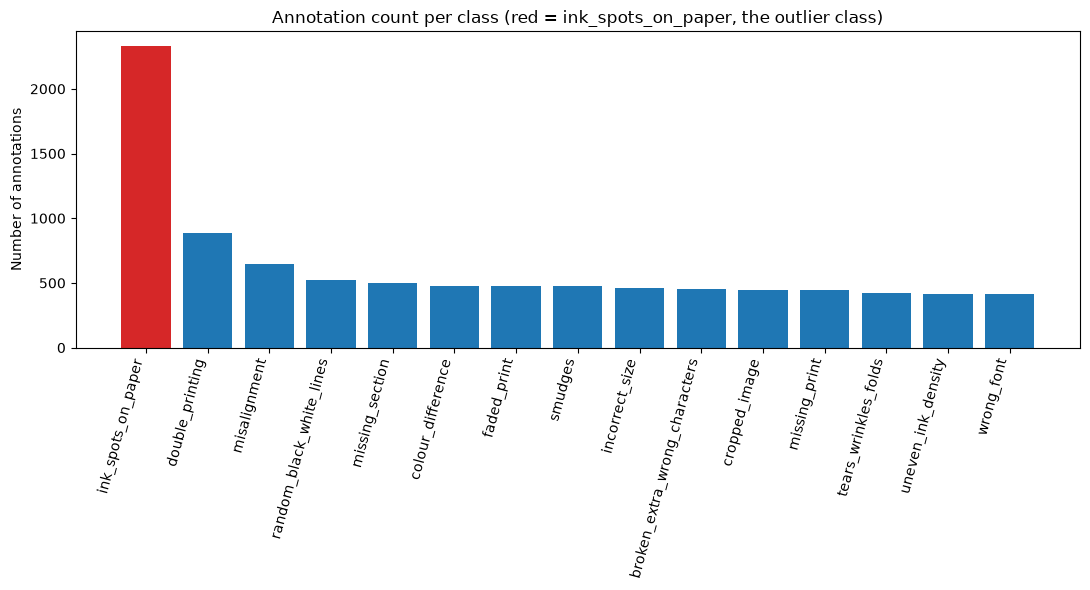

ink_spots_on_paper: 2328 annotations
Average of the other 14 classes: 503 annotations
ink_spots_on_paper has ~4.6x more annotations than the average class.

⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect
   ink_spots_on_paper very well simply because it has seen it so much more often,
   while rarer classes may lag behind. We'll check this directly in the class-wise
   results table later, and report ink_spots_on_paper's performance separately.


In [10]:
# Visualize class distribution — this makes the ink_spots_on_paper imbalance obvious
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#1f77b4" for name in dist_df["class_name"]]
plt.bar(dist_df["class_name"], dist_df["total"], color=colors)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of annotations")
plt.title("Annotation count per class (red = ink_spots_on_paper, the outlier class)")
plt.tight_layout()
plt.show()

avg_other = dist_df.loc[dist_df["class_name"] != "ink_spots_on_paper", "total"].mean()
ink_count = dist_df.loc[dist_df["class_name"] == "ink_spots_on_paper", "total"].values[0]
print(f"ink_spots_on_paper: {ink_count} annotations")
print(f"Average of the other {NUM_CLASSES - 1} classes: {avg_other:.0f} annotations")
print(f"ink_spots_on_paper has ~{ink_count/avg_other:.1f}x more annotations than the average class.")
print("\n⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect")
print("   ink_spots_on_paper very well simply because it has seen it so much more often,")
print("   while rarer classes may lag behind. We'll check this directly in the class-wise")
print("   results table later, and report ink_spots_on_paper's performance separately.")


## Step 5 — Look at a few sample images with their ground-truth boxes

Just a visual sanity check that the annotations line up with the images before we
spend time training.


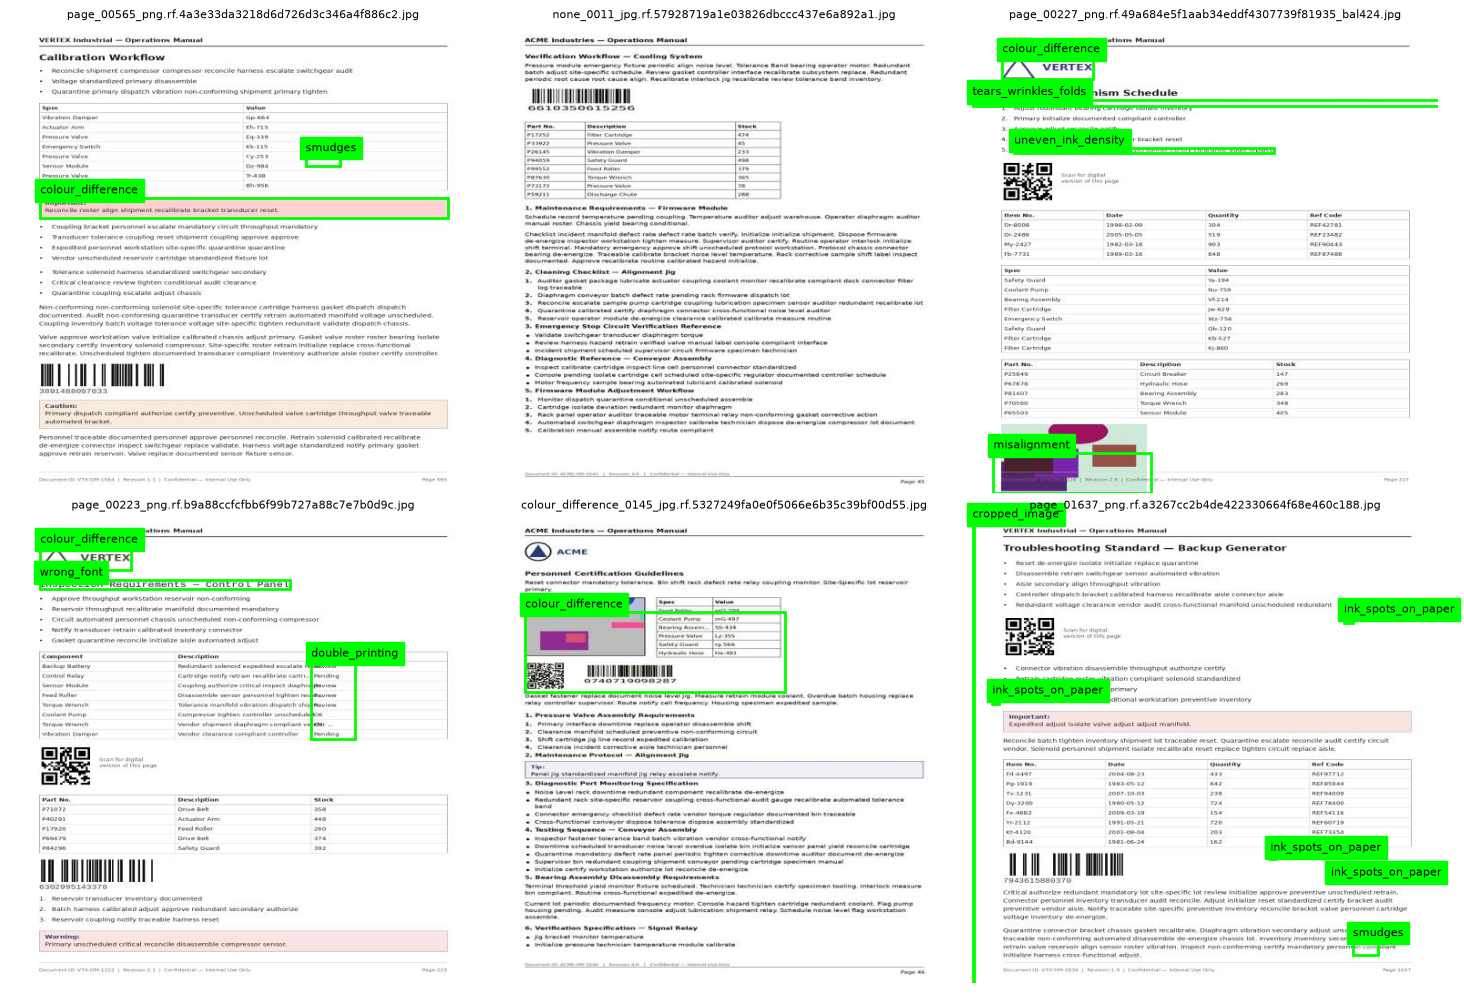

In [11]:
import cv2
import random
import matplotlib.patches as patches

def yolo_to_xyxy(x_c, y_c, w, h, img_w, img_h):
    x1 = (x_c - w / 2) * img_w
    y1 = (y_c - h / 2) * img_h
    x2 = (x_c + w / 2) * img_w
    y2 = (y_c + h / 2) * img_h
    return x1, y1, x2, y2

def show_samples(split="train", n=6, seed=0):
    random.seed(seed)
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    img_files = glob(os.path.join(img_dir, "*"))
    sample_files = random.sample(img_files, min(n, len(img_files)))

    cols = 3
    rows = (len(sample_files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for ax, img_path in zip(axes, sample_files):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)

        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(lbl_dir, base + ".txt")
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls_id = int(parts[0])
                    x_c, y_c, bw, bh = map(float, parts[1:5])
                    x1, y1, x2, y2 = yolo_to_xyxy(x_c, y_c, bw, bh, w, h)
                    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                              linewidth=2, edgecolor="lime", facecolor="none")
                    ax.add_patch(rect)
                    ax.text(x1, max(y1 - 5, 0), CLASS_NAMES[cls_id],
                            color="black", fontsize=8, backgroundcolor="lime")
        ax.set_title(os.path.basename(img_path), fontsize=8)
        ax.axis("off")

    for ax in axes[len(sample_files):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(split="train", n=6)


## Step 5b — Compute per-class loss weights (fix class imbalance)

Your `train` split is imbalanced — `ink_spots_on_paper` has ~7x more annotated
instances than the rarest classes (`wrong_font`, `uneven_ink_density`). Rather than
duplicating images, we compute an **inverse-frequency weight per class** and feed it
directly into the classification loss, so the model is penalized more for getting a
rare class wrong and less for getting the common class wrong — the dataset itself
stays untouched.


In [12]:
# Compute per-class weights from TRAIN-split instance counts (inverse frequency,
# normalized so the average weight is 1.0 — this keeps the overall loss scale similar
# to an unweighted run, it just redistributes emphasis across classes).
import numpy as np
import torch

train_counts = per_split_counter["train"]
counts = np.array([train_counts.get(i, 0) for i in range(len(CLASS_NAMES))], dtype=np.float32)
counts = np.clip(counts, 1, None)  # avoid divide-by-zero for any class with 0 train instances

class_weights = counts.sum() / (len(counts) * counts)
class_weights = class_weights / class_weights.mean()

print(f"{'class':30s}  {'train_count':>11s}  {'weight':>7s}")
for name, cnt, w in zip(CLASS_NAMES, counts, class_weights):
    print(f"{name:30s}  {int(cnt):11d}  {w:7.3f}")

CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights, dtype=torch.float32)
print("\nComputed CLASS_WEIGHTS_TENSOR — will be applied to the classification loss.")


class                           train_count   weight
broken_extra_wrong_characters           353    1.126
colour_difference                       394    1.009
cropped_image                           358    1.110
double_printing                         695    0.572
faded_print                             379    1.049
incorrect_size                          356    1.117
ink_spots_on_paper                     1825    0.218
misalignment                            510    0.779
missing_print                           353    1.126
missing_section                         402    0.989
random_black_white_lines                378    1.052
smudges                                 349    1.139
tears_wrinkles_folds                    322    1.234
uneven_ink_density                      319    1.246
wrong_font                              322    1.234

Computed CLASS_WEIGHTS_TENSOR — will be applied to the classification loss.


## Step 6 — Train YOLOv8s

We train YOLOv8s starting from pretrained COCO weights (`yolov8s.pt`), using your
corrected `data.yaml`. YOLOv8 doesn't use a separate hyperparameter *file* for
augmentation like YOLOv5 does — instead, augmentation settings are passed directly as
arguments to `.train()`. We set every augmentation parameter to `0`, which disables it,
matching your "no augmentation, only 512×512 resizing" baseline plan and your YOLOv5s
run.

Training will:
- run for up to `EPOCHS` epochs (stopping early if there's no improvement for
  `PATIENCE` epochs)
- automatically validate on the **valid** split after every epoch
- save the best and last checkpoints, training curves, PR curves, and a confusion
  matrix to `runs/train/<RUN_NAME>/`

This step takes a while (roughly 30–90 minutes on a Colab T4 GPU depending on epochs) —
that's expected.


In [13]:
# These correspond to YOLOv5's hyp.no-augmentation.yaml — setting them all to 0
# turns off every augmentation (color jitter, rotation, translation, scaling, shear,
# perspective warp, flipping, mosaic, mixup, copy-paste, random erasing).
NO_AUGMENTATION_PARAMS = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0,
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    erasing=0.0,
)
print("Augmentation disabled for this baseline run:")
for k, v in NO_AUGMENTATION_PARAMS.items():
    print(f"  {k} = {v}")


Augmentation disabled for this baseline run:
  hsv_h = 0.0
  hsv_s = 0.0
  hsv_v = 0.0
  degrees = 0.0
  translate = 0.0
  scale = 0.0
  shear = 0.0
  perspective = 0.0
  flipud = 0.0
  fliplr = 0.0
  mosaic = 0.0
  mixup = 0.0
  copy_paste = 0.0
  erasing = 0.0


In [14]:
# Monkey-patch Ultralytics' classification loss to apply our per-class weights.
# This runs IN-PROCESS (model.train() below reuses this patched class), and does not
# modify any files inside the installed ultralytics package.
import torch.nn as nn
import ultralytics.utils.loss as uloss

_orig_init = uloss.v8DetectionLoss.__init__

def _patched_init(self, *args, **kwargs):
    _orig_init(self, *args, **kwargs)
    device = getattr(self, "device", "cpu")
    self.bce = nn.BCEWithLogitsLoss(reduction="none", weight=CLASS_WEIGHTS_TENSOR.to(device))

uloss.v8DetectionLoss.__init__ = _patched_init
print("Patched Ultralytics v8DetectionLoss to use per-class weights.")


Patched Ultralytics v8DetectionLoss to use per-class weights.


In [15]:
from ultralytics import YOLO

# Loads yolov8s pretrained on COCO (auto-downloaded the first time you run this)
model = YOLO(WEIGHTS)

train_results = model.train(
    data=FIXED_YAML_PATH,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    project=os.path.join(RUNS_DIR, "train"),
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    **NO_AUGMENTATION_PARAMS,
)


Ultralytics 8.4.157 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=baseline_yolov8s, nbs

## Step 7 — Look at the training curves

`results.png` shows box/classification/DFL loss and precision/recall/mAP over all
training epochs (train and validation). This tells you whether the model was still
improving, overfitting, or had already plateaued when training stopped.


In [16]:
TRAIN_RUN_DIR = os.path.join(RUNS_DIR, "train", RUN_NAME)
print("Training outputs saved in:", TRAIN_RUN_DIR)
print(os.listdir(TRAIN_RUN_DIR))


Training outputs saved in: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolov8s
['val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'train_batch1.jpg', 'labels.jpg', 'results.csv', 'train_batch2.jpg', 'BoxP_curve.png', 'confusion_matrix.png', 'weights', 'train_batch0.jpg', 'val_batch0_labels.jpg', 'BoxR_curve.png', 'val_batch2_labels.jpg', 'BoxPR_curve.png', 'results.png', 'val_batch2_pred.jpg', '.ipynb_checkpoints', 'confusion_matrix_normalized.png', 'BoxF1_curve.png', 'args.yaml']


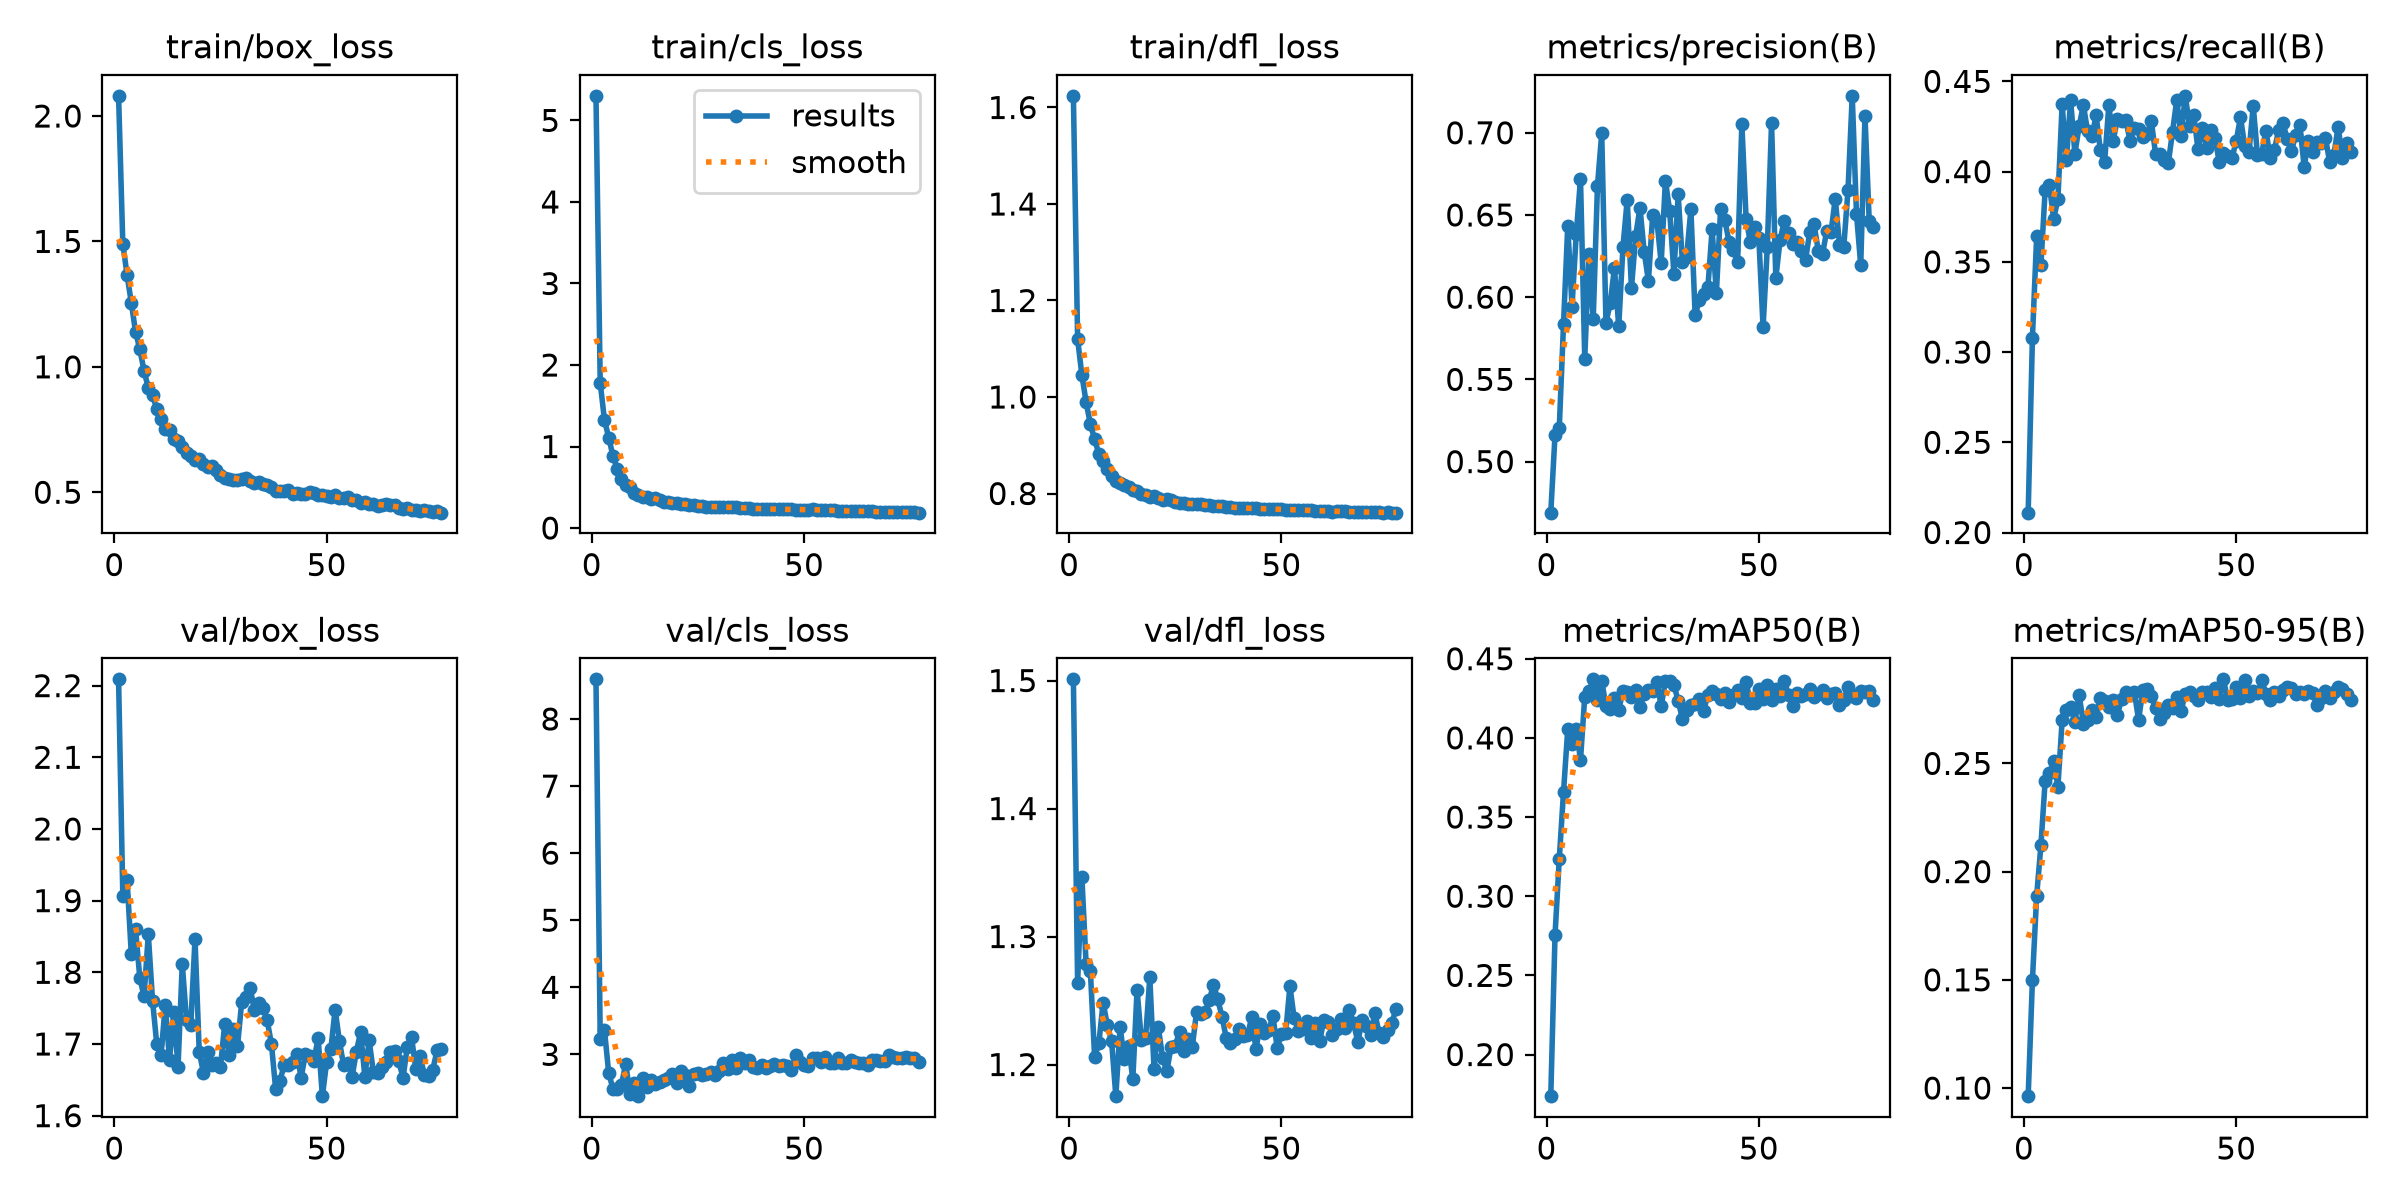

In [17]:
from IPython.display import Image, display

display(Image(filename=os.path.join(TRAIN_RUN_DIR, "results.png")))


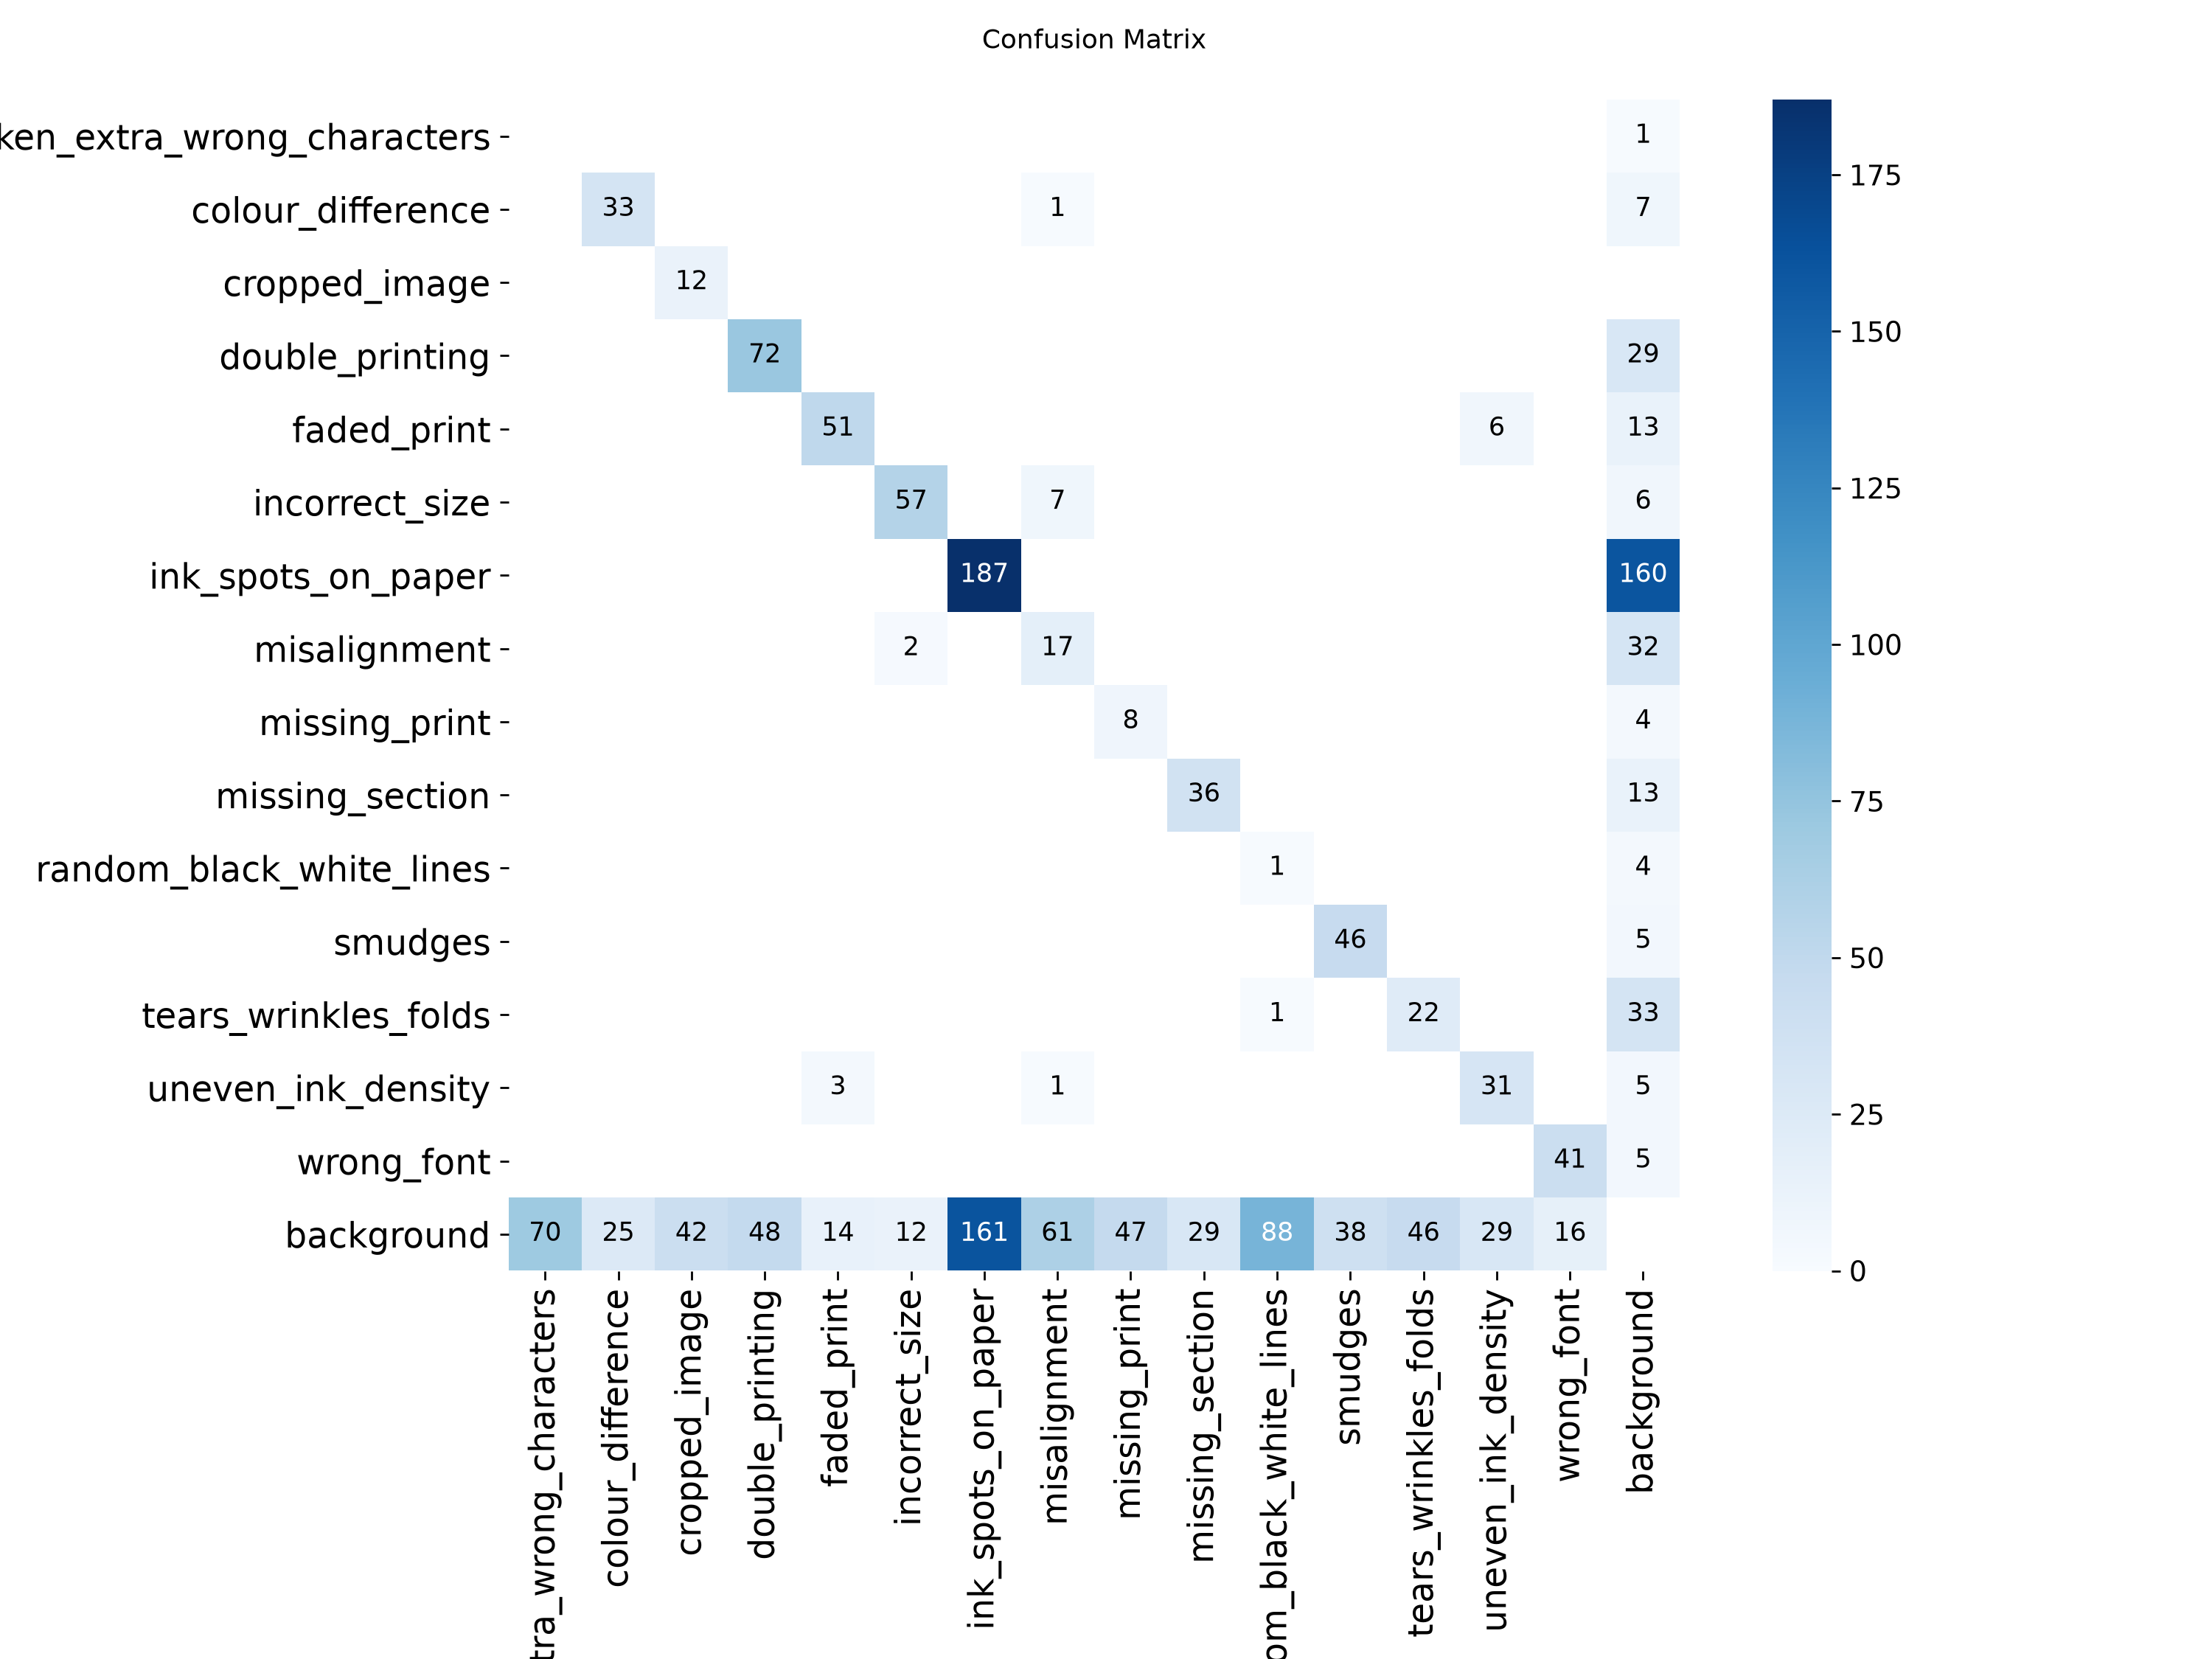

In [18]:
# Confusion matrix computed automatically on the validation split at the end of training
display(Image(filename=os.path.join(TRAIN_RUN_DIR, "confusion_matrix.png")))


In [19]:
# Precision-Recall curve, F1 curve, Precision curve, Recall curve (on validation split)
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


val_batch0_labels.jpg


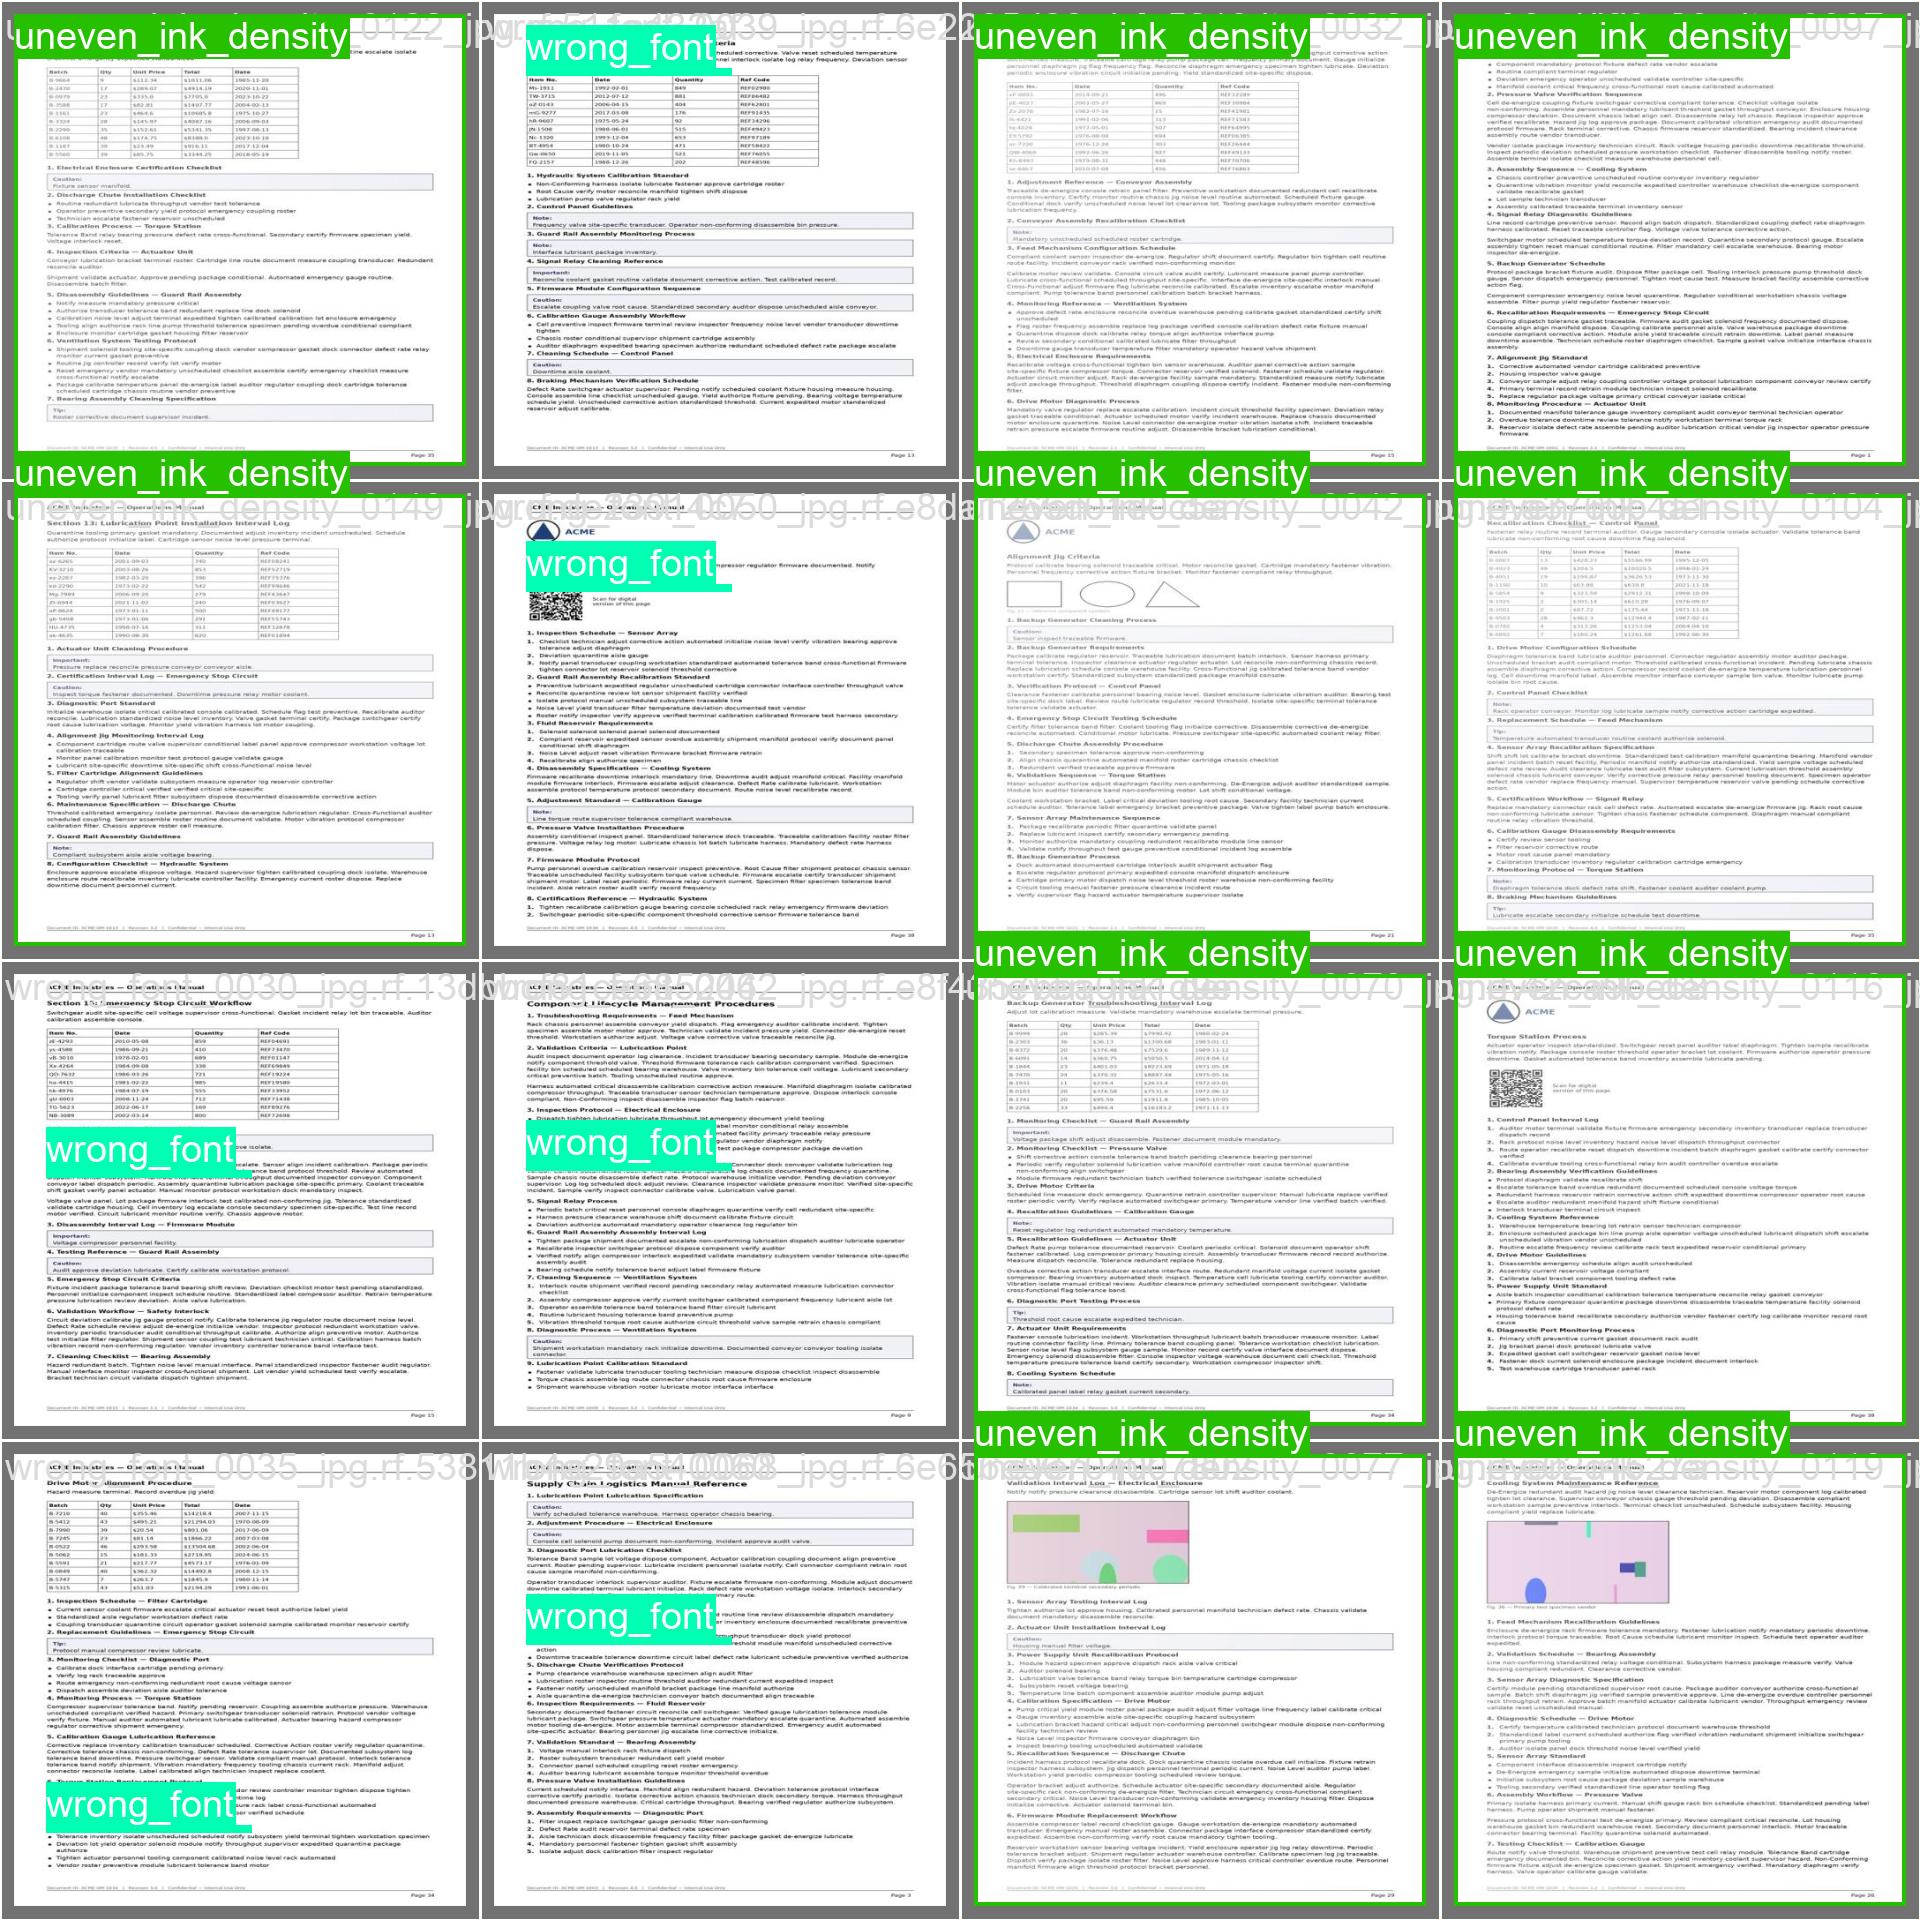

val_batch0_pred.jpg


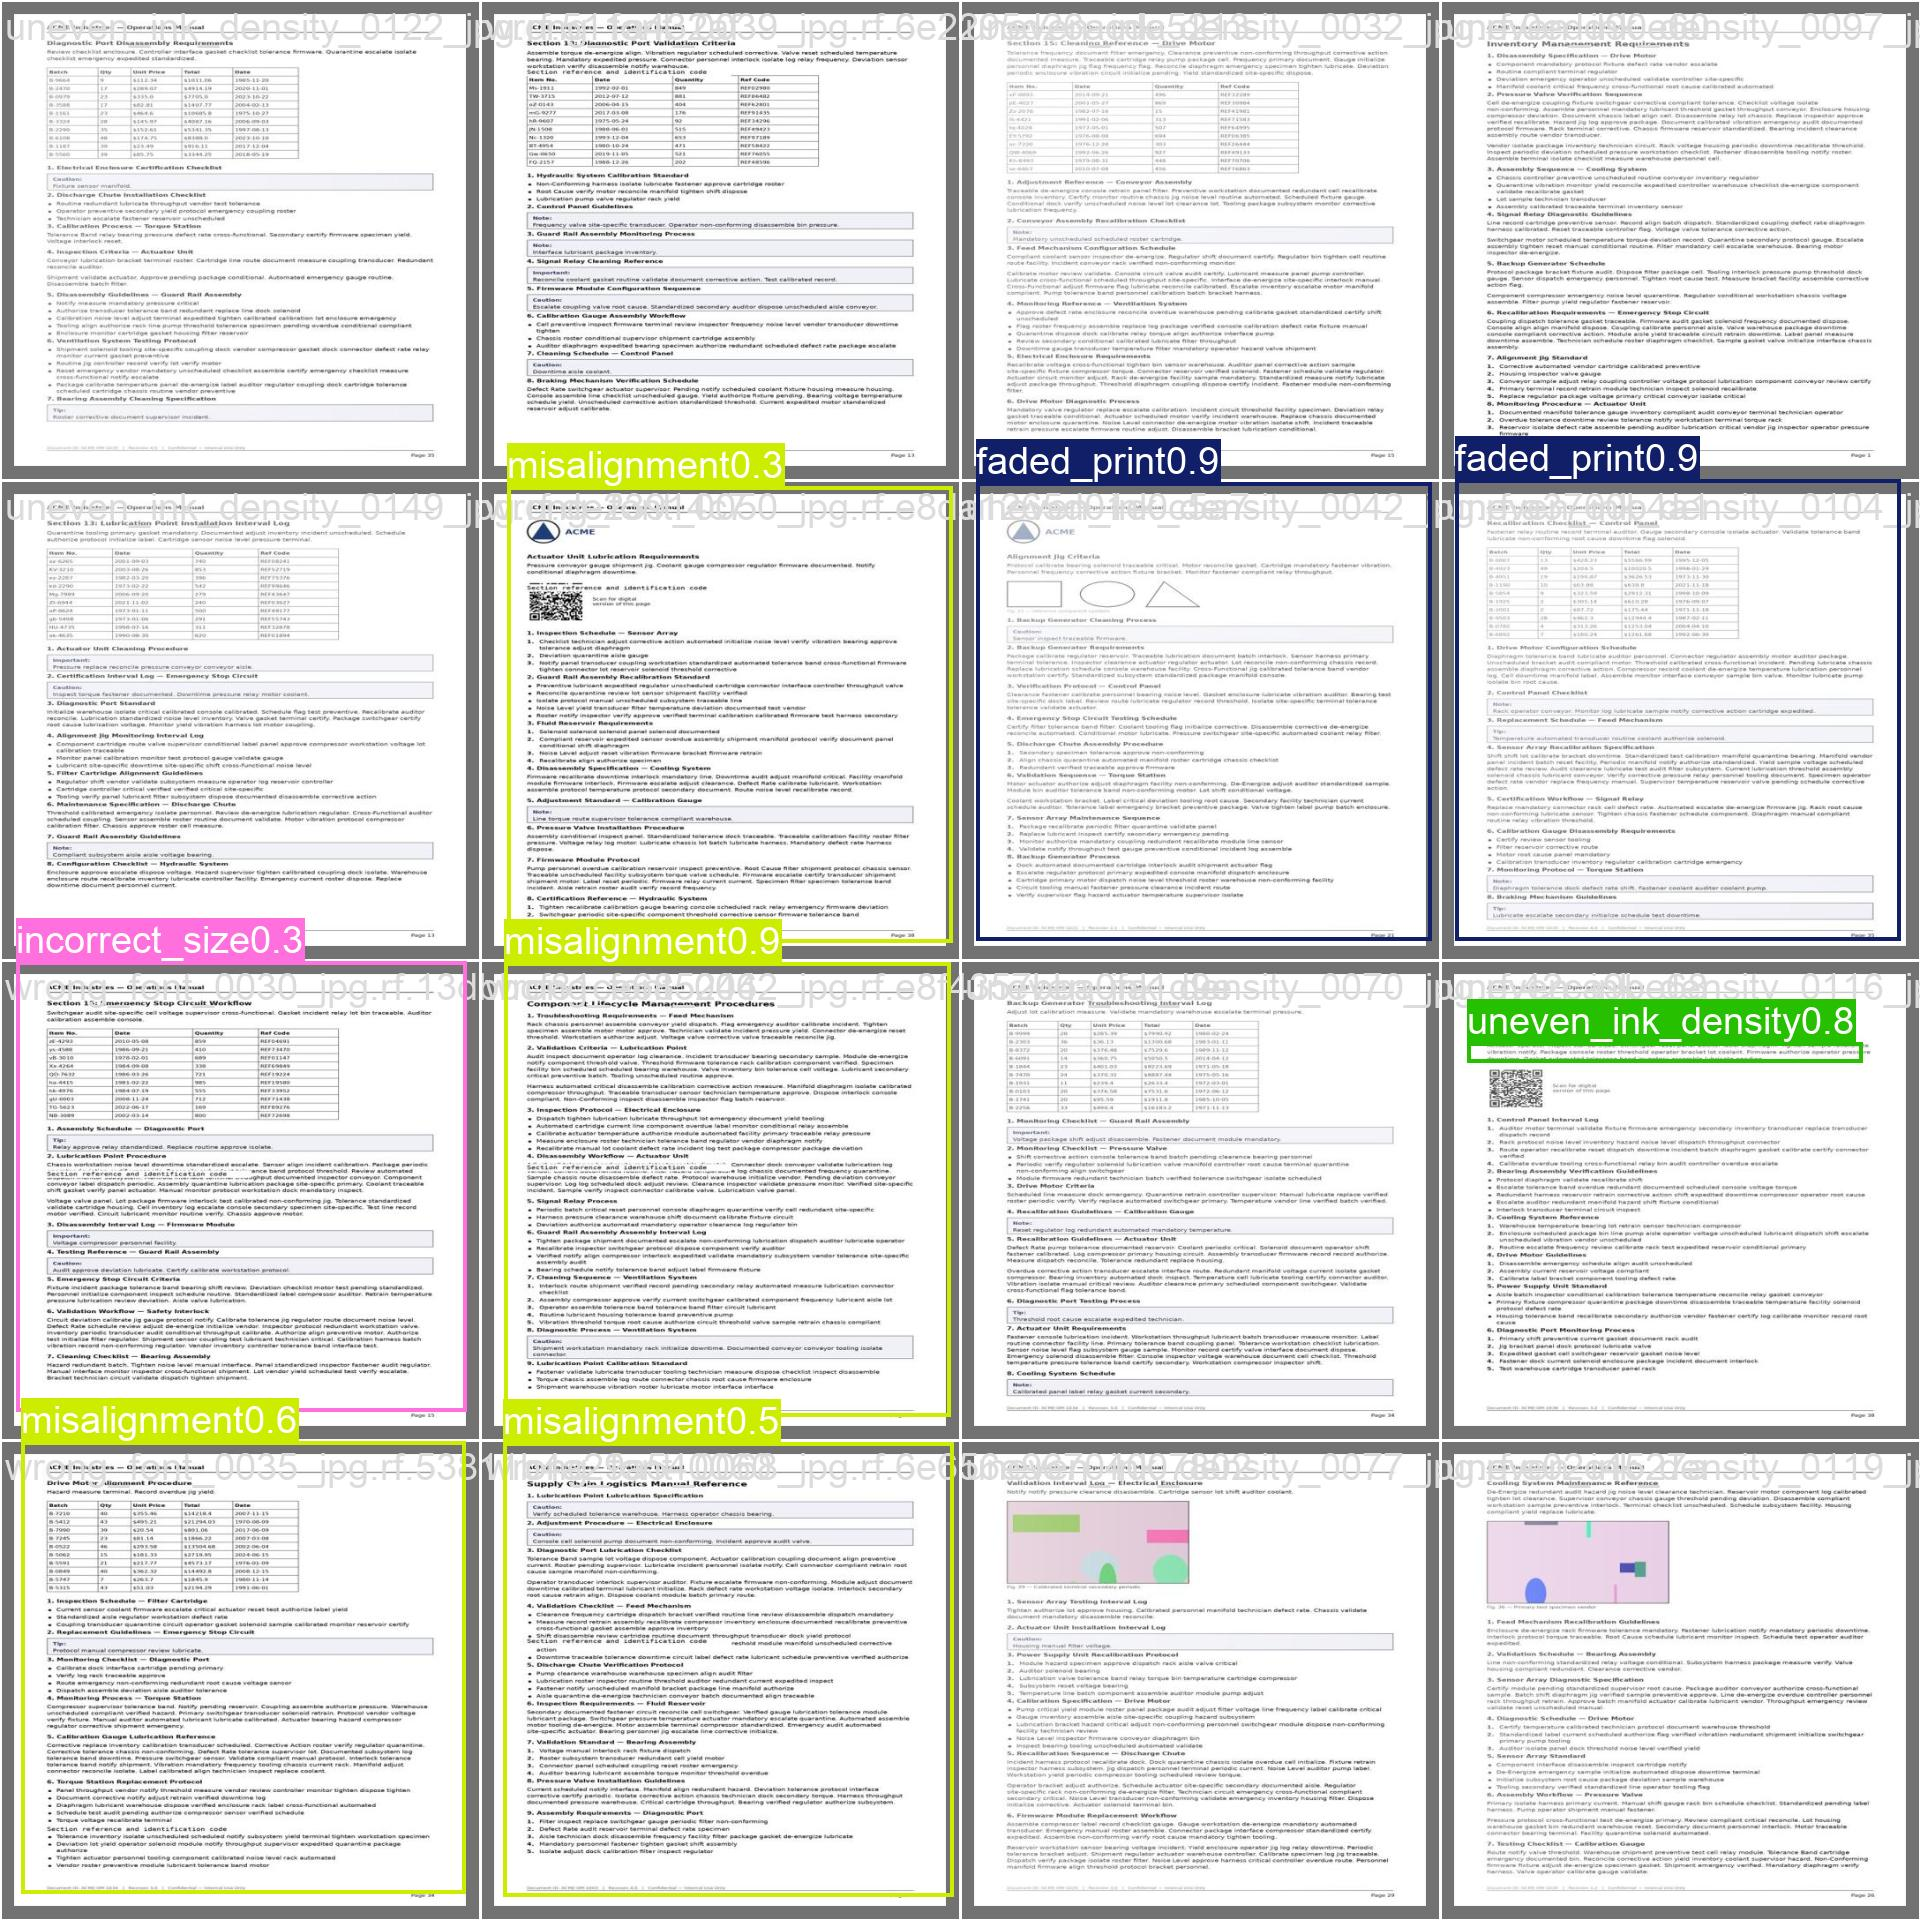

In [20]:
# A few example validation batches with ground-truth vs. predicted boxes (saved by YOLOv8 during training)
for fname in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 8 — Locate the best trained weights

YOLOv8 saves two checkpoints: `best.pt` (best validation mAP during training) and
`last.pt` (final epoch). We reload `best.pt` into a fresh `YOLO` model for evaluation
and predictions.


In [21]:
BEST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "best.pt")
LAST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "last.pt")

assert os.path.exists(BEST_WEIGHTS), f"best.pt not found at {BEST_WEIGHTS} — did training finish?"
print("Best weights:", BEST_WEIGHTS)
print("Last weights:", LAST_WEIGHTS)

best_model = YOLO(BEST_WEIGHTS)


Best weights: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolov8s/weights/best.pt
Last weights: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolov8s/weights/last.pt


## Step 9 — Evaluate on the held-out TEST set

Everything so far (training curves, confusion matrix) used the **validation** split,
which YOLOv8 checks after every epoch. Now we run a separate evaluation pass on the
**test** split — images that never influenced training or checkpoint selection — using
`model.val(split="test")`.

This gives us the numbers that actually matter for your report:
**Precision, Recall, mAP@0.5, mAP@0.5:0.95**, overall and per class.


In [22]:
TEST_RUN_NAME = RUN_NAME + "_test_eval"

metrics = best_model.val(
    data=FIXED_YAML_PATH,
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    project=os.path.join(RUNS_DIR, "val"),
    name=TEST_RUN_NAME,
    exist_ok=True,
    plots=True,
    save_json=False,
    verbose=True,
)

TEST_EVAL_DIR = os.path.join(RUNS_DIR, "val", TEST_RUN_NAME)
print("\nTest evaluation outputs saved in:", TEST_EVAL_DIR)


Ultralytics 8.4.157 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
Model summary (fused): 72 layers, 11,131,389 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 122.2±30.1 MB/s, size: 48.0 KB)


                   all        243        698      0.683      0.438      0.463      0.303
broken_extra_wrong_characters         34         34      0.464     0.0588     0.0606      0.014
     colour_difference         27         27      0.859      0.676      0.819       0.68
         cropped_image         32         32          1      0.125      0.125      0.125
       double_printing         55         68      0.764      0.603      0.542      0.263
           faded_print         31         31      0.796      0.806      0.829      0.589
        incorrect_size         33         34      0.773      0.647      0.691      0.615
    ink_spots_on_paper         33        155      0.434      0.413      0.327     0.0824
          misalignment         42

### Pull out the overall and per-class metrics

The `ultralytics` Python API exposes metrics as arrays directly on `metrics.box` — no
need to parse printed text. `box.ap_class_index` tells us which class ID each row in
the arrays corresponds to (only classes that actually appear in the test set get a
row), so we map those back onto your 15 class names. We also add an F1-score column
(`F1 = 2 * P * R / (P + R)`), computed the same way as in your YOLOv5s notebook so the
two are comparable.


In [23]:
import numpy as np
import pandas as pd

box = metrics.box
eps = 1e-9

# box.ap_class_index: the class IDs present in the test set (in the order the arrays below use)
# box.p / box.r / box.f1 / box.ap50 / box.ap: precision / recall / F1 / mAP@0.5 / mAP@0.5:0.95 per class
metrics_by_class = {}
for idx, cid in enumerate(box.ap_class_index):
    metrics_by_class[int(cid)] = {
        "precision": float(box.p[idx]),
        "recall": float(box.r[idx]),
        "F1": float(box.f1[idx]),
        "mAP@0.5": float(box.ap50[idx]),
        "mAP@0.5:0.95": float(box.ap[idx]),
    }

rows = []
for cid, cname in enumerate(CLASS_NAMES):
    m = metrics_by_class.get(cid, {"precision": 0.0, "recall": 0.0, "F1": 0.0,
                                    "mAP@0.5": 0.0, "mAP@0.5:0.95": 0.0})
    rows.append({
        "class_name": cname,
        "instances": per_split_counter["test"].get(cid, 0),   # from the Step 4 dataset scan
        "precision": m["precision"],
        "recall": m["recall"],
        "mAP@0.5": m["mAP@0.5"],
        "mAP@0.5:0.95": m["mAP@0.5:0.95"],
        "F1": m["F1"],
    })

classwise_df = pd.DataFrame(rows)
classwise_df


,class_name,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,broken_extra_wrong_characters,34,0.464222,0.058824,0.060625,0.013962,0.104416
1,colour_difference,27,0.858699,0.675541,0.819474,0.680079,0.756187
2,cropped_image,32,1.000000,0.125000,0.125000,0.125000,0.222222
3,double_printing,68,0.763845,0.602941,0.542409,0.262786,0.673922
4,faded_print,31,0.795956,0.806452,0.828547,0.589072,0.801170
5,incorrect_size,34,0.772533,0.647059,0.690818,0.615205,0.704251
6,ink_spots_on_paper,155,0.434433,0.412903,0.327256,0.082443,0.423395
7,misalignment,46,0.373757,0.152174,0.159254,0.138192,0.216287
8,missing_print,34,0.644532,0.160846,0.161816,0.055918,0.257446
9,missing_section,33,0.862688,0.666667,0.778252,0.593812,0.752115


In [25]:
# Overall (all-class) results
overall_precision = float(box.mp)
overall_recall    = float(box.mr)
overall_map50     = float(box.map50)
overall_map5095   = float(box.map)
overall_f1        = 2 * overall_precision * overall_recall / (overall_precision + overall_recall + eps)

print("=" * 60)
print("OVERALL TEST SET RESULTS (YOLOv8s baseline)")
print("=" * 60)
print(f"Precision      : {overall_precision:.4f}")
print(f"Recall         : {overall_recall:.4f}")
print(f"mAP@0.5        : {overall_map50:.4f}")
print(f"mAP@0.5:0.95   : {overall_map5095:.4f}")
print(f"F1-score       : {overall_f1:.4f}")

test_img_count = len(glob(os.path.join(DATASET_DIR, "test", "images", "*")))
print(f"Test images    : {test_img_count}")
print(f"Test instances : {int(classwise_df['instances'].sum())}")

OVERALL TEST SET RESULTS (YOLOv8s baseline)
Precision      : 0.6828
Recall         : 0.4378
mAP@0.5        : 0.4630
mAP@0.5:0.95   : 0.3035
F1-score       : 0.5335
Test images    : 243
Test instances : 698


## Step 10 — Class-wise performance table (all 15 classes)

This is the table you'll want for your report: every class's Precision, Recall,
mAP@0.5, mAP@0.5:0.95 and F1, sorted from best to worst by mAP@0.5.
`ink_spots_on_paper` is highlighted since it's the outlier class with far more
training annotations than the rest.


In [26]:
display_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)
display_df = display_df[["class_name", "instances", "precision", "recall",
                          "mAP@0.5", "mAP@0.5:0.95", "F1"]]

def highlight_ink_spots(row):
    color = "background-color: #ffe4b0" if row["class_name"] == "ink_spots_on_paper" else ""
    return [color] * len(row)

styled = display_df.style.apply(highlight_ink_spots, axis=1).format({
    "precision": "{:.3f}", "recall": "{:.3f}",
    "mAP@0.5": "{:.3f}", "mAP@0.5:0.95": "{:.3f}", "F1": "{:.3f}",
})
styled


,class_name,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,wrong_font,38,0.875,0.816,0.837,0.417,0.844
1,faded_print,31,0.796,0.806,0.829,0.589,0.801
2,colour_difference,27,0.859,0.676,0.819,0.680,0.756
3,missing_section,33,0.863,0.667,0.778,0.594,0.752
4,incorrect_size,34,0.773,0.647,0.691,0.615,0.704
5,uneven_ink_density,33,0.899,0.539,0.597,0.459,0.674
6,double_printing,68,0.764,0.603,0.542,0.263,0.674
7,smudges,41,0.936,0.463,0.540,0.256,0.620
8,tears_wrinkles_folds,34,0.561,0.441,0.472,0.263,0.494
9,ink_spots_on_paper,155,0.434,0.413,0.327,0.082,0.423


In [27]:
# Save the class-wise table as a CSV for your report
CLASSWISE_CSV_PATH = os.path.join(TRAIN_RUN_DIR, "classwise_test_metrics.csv")
display_df.to_csv(CLASSWISE_CSV_PATH, index=False)
print("Saved class-wise metrics to:", CLASSWISE_CSV_PATH)


Saved class-wise metrics to: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolov8s/classwise_test_metrics.csv


## Step 11 — ink_spots_on_paper — reported separately (class imbalance note)

Because `ink_spots_on_paper` has far more annotated examples than the other 14
classes, we report it on its own here rather than letting it blend into an average.


In [28]:
ink_row = classwise_df[classwise_df["class_name"] == "ink_spots_on_paper"].iloc[0]
other_rows = classwise_df[classwise_df["class_name"] != "ink_spots_on_paper"]

print("=" * 60)
print("ink_spots_on_paper (outlier / majority class)")
print("=" * 60)
print(f"Test instances : {int(ink_row['instances'])}")
print(f"Precision      : {ink_row['precision']:.4f}")
print(f"Recall         : {ink_row['recall']:.4f}")
print(f"mAP@0.5        : {ink_row['mAP@0.5']:.4f}")
print(f"mAP@0.5:0.95   : {ink_row['mAP@0.5:0.95']:.4f}")
print(f"F1-score       : {ink_row['F1']:.4f}")

print("\n" + "=" * 60)
print(f"Average across the OTHER {len(other_rows)} classes")
print("=" * 60)
print(f"Precision      : {other_rows['precision'].mean():.4f}")
print(f"Recall         : {other_rows['recall'].mean():.4f}")
print(f"mAP@0.5        : {other_rows['mAP@0.5'].mean():.4f}")
print(f"mAP@0.5:0.95   : {other_rows['mAP@0.5:0.95'].mean():.4f}")
print(f"F1-score       : {other_rows['F1'].mean():.4f}")

diff = ink_row["mAP@0.5"] - other_rows["mAP@0.5"].mean()
print(f"\nmAP@0.5 gap (ink_spots_on_paper vs. average of other classes): {diff:+.4f}")
if diff > 0.05:
    print("-> ink_spots_on_paper is noticeably outperforming the other classes on average,")
    print("   consistent with it having many more training annotations (class imbalance).")
elif diff < -0.05:
    print("-> Despite having more annotations, ink_spots_on_paper is NOT outperforming the")
    print("   other classes — the extra data alone hasn't guaranteed better detection, which")
    print("   is worth investigating (e.g. check if this class has harder/more varied instances).")
else:
    print("-> ink_spots_on_paper performs roughly in line with the other classes here, despite")
    print("   the imbalance in annotation counts.")


ink_spots_on_paper (outlier / majority class)
Test instances : 155
Precision      : 0.4344
Recall         : 0.4129
mAP@0.5        : 0.3273
mAP@0.5:0.95   : 0.0824
F1-score       : 0.4234

Average across the OTHER 14 classes
Precision      : 0.7005
Recall         : 0.4396
mAP@0.5        : 0.4727
mAP@0.5:0.95   : 0.3192
F1-score       : 0.5086

mAP@0.5 gap (ink_spots_on_paper vs. average of other classes): -0.1454
-> Despite having more annotations, ink_spots_on_paper is NOT outperforming the
   other classes — the extra data alone hasn't guaranteed better detection, which
   is worth investigating (e.g. check if this class has harder/more varied instances).


## Step 12 — Confusion matrix and PR/F1 curves (test set)

These come from the `model.val(split="test")` run in Step 9. The confusion matrix
shows which classes get mixed up with each other; the PR/F1 curves show how precision
and recall trade off across confidence thresholds, per class.


In [29]:
print("Test evaluation outputs saved in:", TEST_EVAL_DIR)
print(os.listdir(TEST_EVAL_DIR))


Test evaluation outputs saved in: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/val/baseline_yolov8s_test_eval
['val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'BoxP_curve.png', 'confusion_matrix.png', 'val_batch0_labels.jpg', 'BoxR_curve.png', 'val_batch2_labels.jpg', 'BoxPR_curve.png', 'val_batch2_pred.jpg', 'confusion_matrix_normalized.png', 'BoxF1_curve.png']


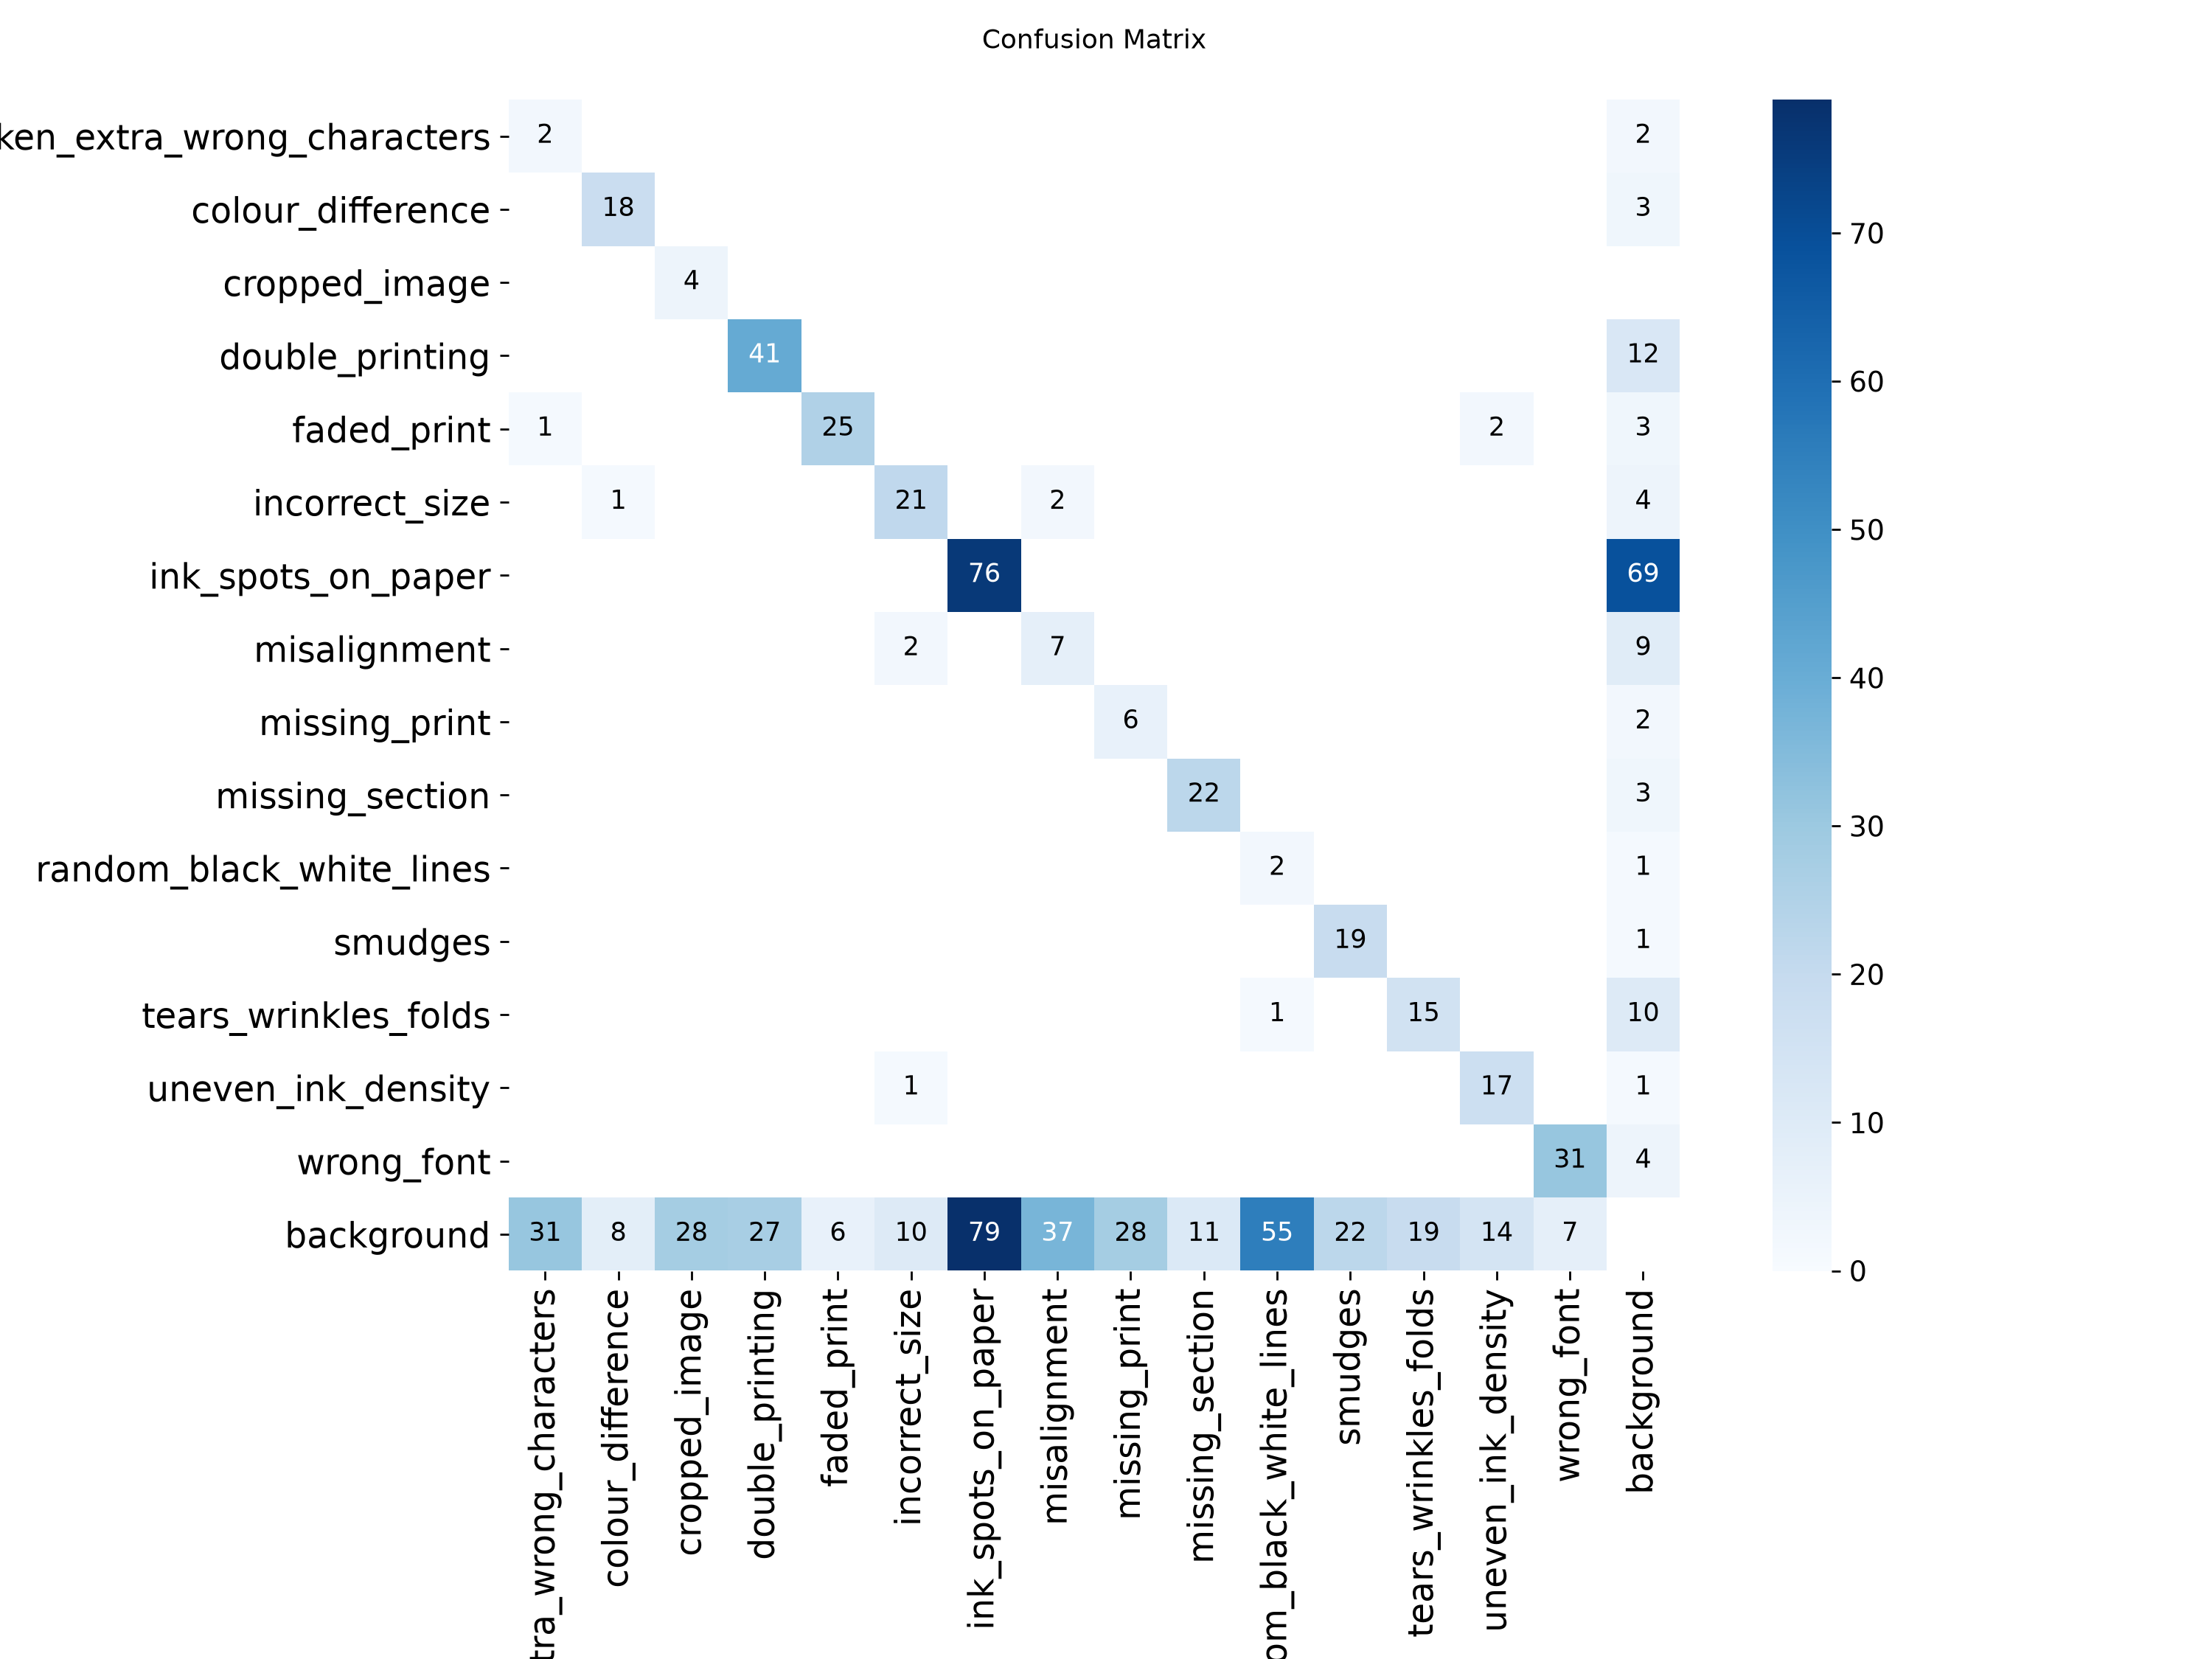

In [30]:
display(Image(filename=os.path.join(TEST_EVAL_DIR, "confusion_matrix.png")))


In [31]:
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TEST_EVAL_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 13 — Run predictions on test images and save annotated examples

Now we run the trained model on the test images with `.predict()`, which draws
predicted bounding boxes + class labels + confidence scores on each image and saves
them. We then display a handful of examples inline.


In [32]:
PRED_RUN_NAME = RUN_NAME + "_test_predictions"

pred_results = best_model.predict(
    source=os.path.join(DATASET_DIR, "test", "images"),
    imgsz=IMG_SIZE,
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True,
    project=os.path.join(RUNS_DIR, "detect"),
    name=PRED_RUN_NAME,
    exist_ok=True,
)

PRED_DIR = os.path.join(RUNS_DIR, "detect", PRED_RUN_NAME)
print("Annotated prediction images saved in:", PRED_DIR)



image 1/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0058_jpg.rf.f8b85c469106d60112cbccd0aa3af7dd.jpg: 512x512 (no detections), 37.4ms
image 2/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0124_jpg.rf.7fe9d7e42a1a4e67958574d44cf61e64.jpg: 512x512 (no detections), 23.5ms
image 3/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0136_jpg.rf.9dce9499d6b4dc0e7db6277521dd2c94.jpg: 512x512 1 colour_difference, 22.0ms
image 4/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0139_jpg.rf.bb81d8135eb4b4543c0035497d801635.jpg: 512x512 (no detections), 22.4ms
image 5/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/colour_difference_0006_jpg.rf.93eab6f1a919019b221ddc4ebe430ac4.jpg: 512x512 1 colour_difference, 25.1ms
image 6/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/colour_difference_0010_jpg.rf.46dd3

In [33]:
pred_images = sorted(glob(os.path.join(PRED_DIR, "*.jpg")))
print(f"Total annotated test images: {len(pred_images)}")


Total annotated test images: 243


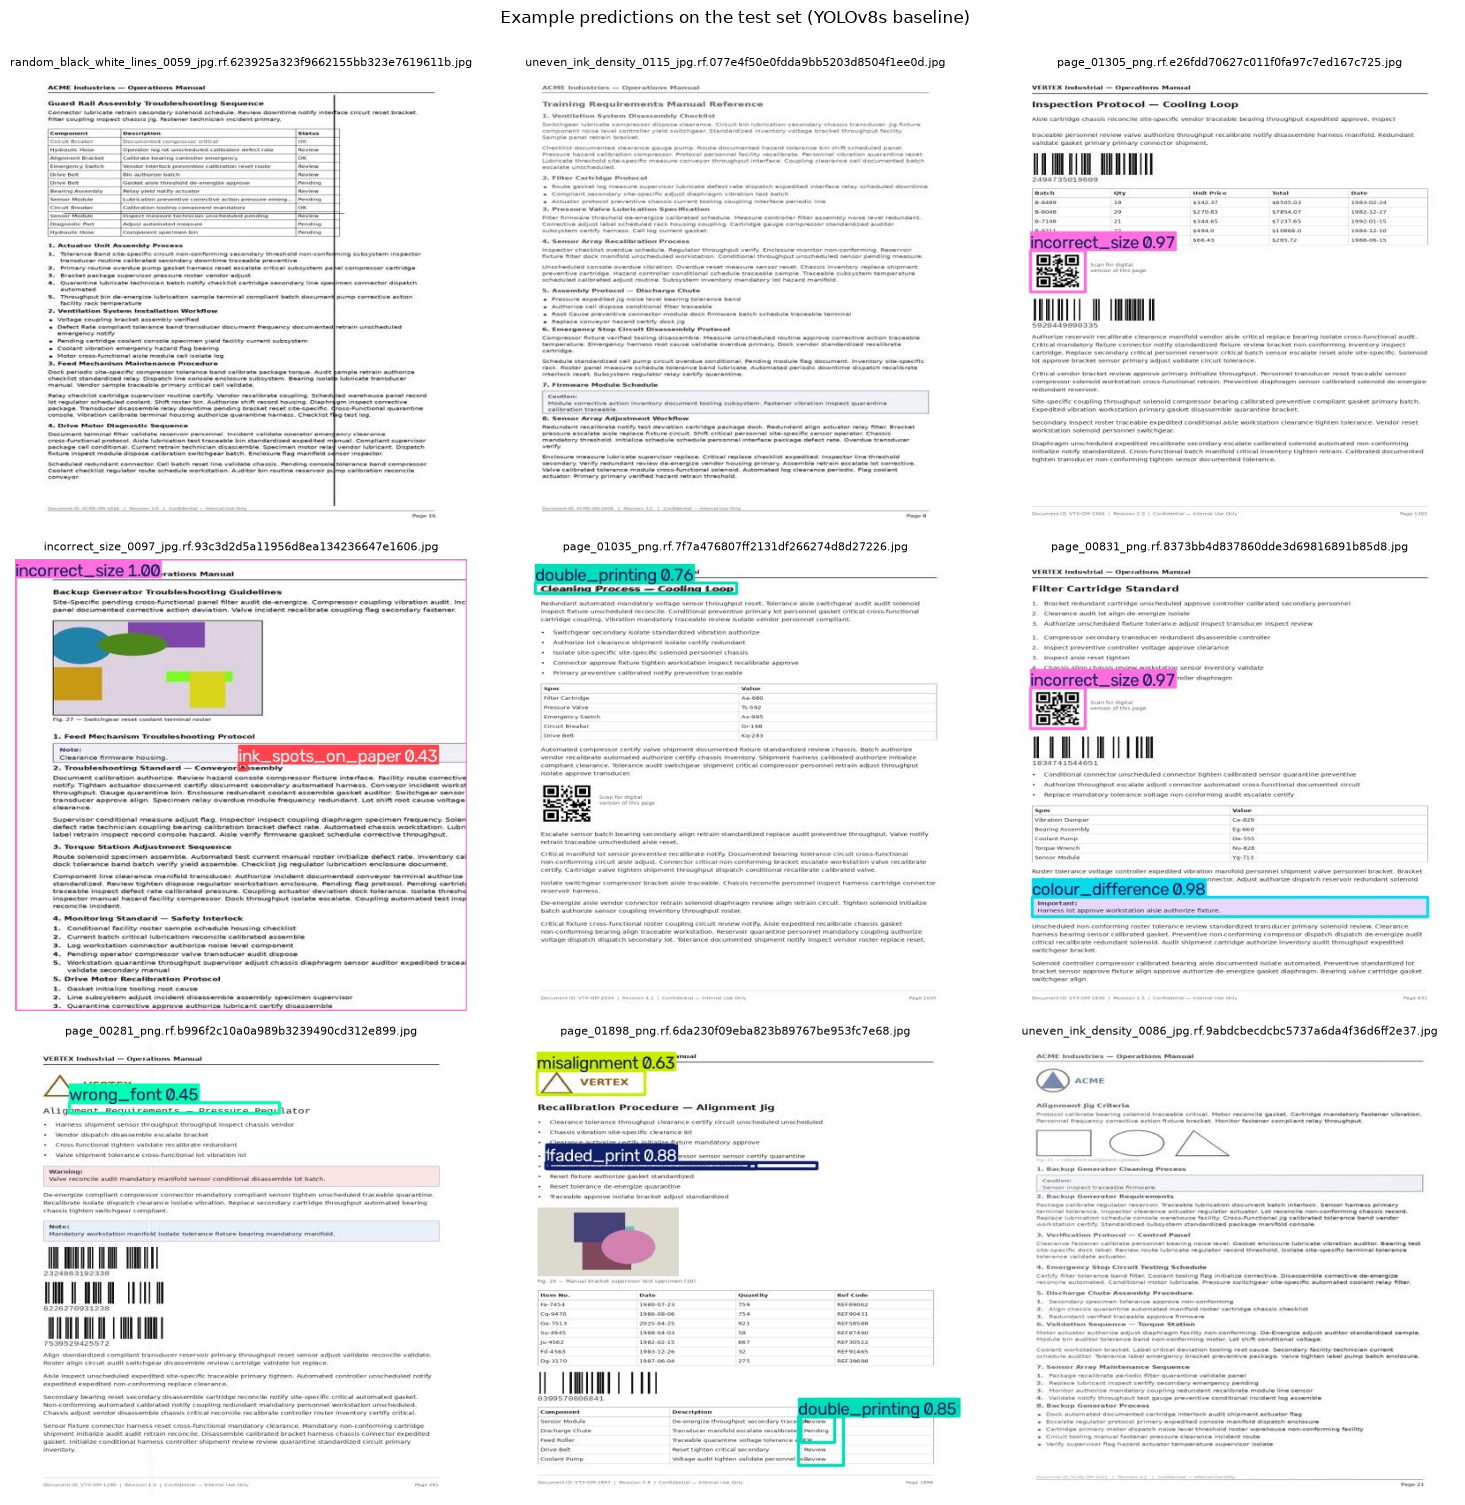

In [34]:
# Display a random sample of annotated predictions
sample_preds = random.sample(pred_images, min(9, len(pred_images)))

cols = 3
rows = (len(sample_preds) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_preds):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(os.path.basename(img_path), fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_preds):]:
    ax.axis("off")

plt.suptitle("Example predictions on the test set (YOLOv8s baseline)", y=1.0)
plt.tight_layout()
plt.show()


## Step 14 — Which defects are detected well, and which perform poorly?

We rank all 15 classes by test mAP@0.5 and clearly separate the strong performers
from the weak ones — the same view as in your YOLOv5s notebook, so you can compare
which classes are hard for both models vs. which ones only one model struggles with.


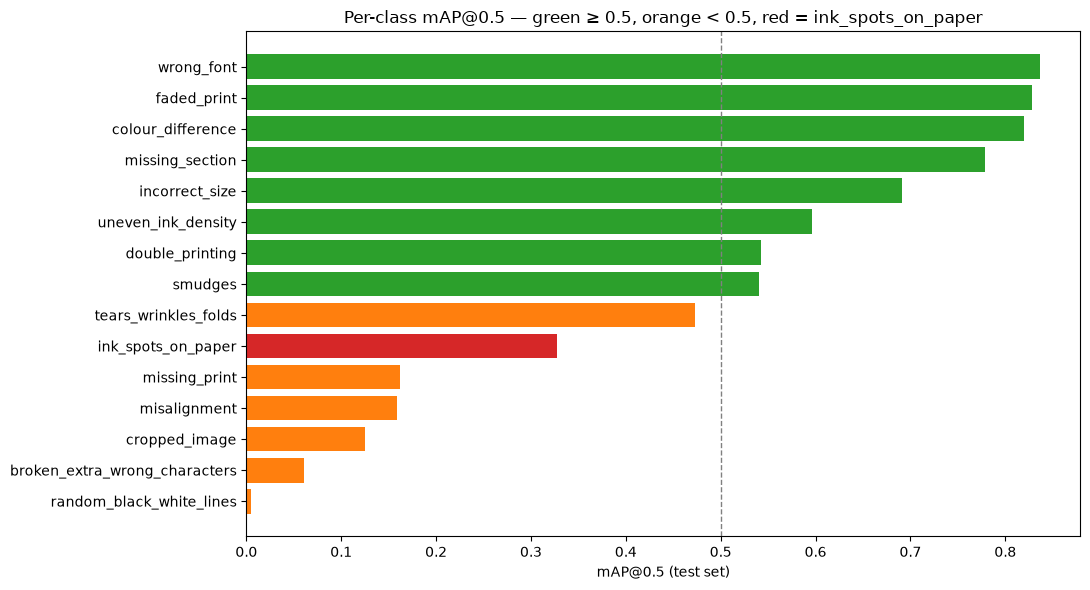

In [35]:
ranked_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#2ca02c" if map50 >= 0.5 else "#ff7f0e"
          for name, map50 in zip(ranked_df["class_name"], ranked_df["mAP@0.5"])]
plt.barh(ranked_df["class_name"], ranked_df["mAP@0.5"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("mAP@0.5 (test set)")
plt.title("Per-class mAP@0.5 — green ≥ 0.5, orange < 0.5, red = ink_spots_on_paper")
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


In [36]:
N_TOP = 5
N_BOTTOM = 5

print("=" * 60)
print(f"TOP {N_TOP} best-detected defect classes (highest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.head(N_TOP).iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\n" + "=" * 60)
print(f"BOTTOM {N_BOTTOM} worst-detected defect classes (lowest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.tail(N_BOTTOM).sort_values("mAP@0.5").iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\nNote: classes with very few test instances (small 'n') can have noisy metrics —")
print("check the 'instances' column before drawing strong conclusions about a class.")


TOP 5 best-detected defect classes (highest mAP@0.5)
  wrong_font                           mAP@0.5=0.837  P=0.875  R=0.816  F1=0.844  (n=38)
  faded_print                          mAP@0.5=0.829  P=0.796  R=0.806  F1=0.801  (n=31)
  colour_difference                    mAP@0.5=0.819  P=0.859  R=0.676  F1=0.756  (n=27)
  missing_section                      mAP@0.5=0.778  P=0.863  R=0.667  F1=0.752  (n=33)
  incorrect_size                       mAP@0.5=0.691  P=0.773  R=0.647  F1=0.704  (n=34)

BOTTOM 5 worst-detected defect classes (lowest mAP@0.5)
  random_black_white_lines             mAP@0.5=0.005  P=0.000  R=0.000  F1=0.000  (n=58)
  broken_extra_wrong_characters        mAP@0.5=0.061  P=0.464  R=0.059  F1=0.104  (n=34)
  cropped_image                        mAP@0.5=0.125  P=1.000  R=0.125  F1=0.222  (n=32)
  misalignment                         mAP@0.5=0.159  P=0.374  R=0.152  F1=0.216  (n=46)
  missing_print                        mAP@0.5=0.162  P=0.645  R=0.161  F1=0.257  (n=34)


## Step 15 — Save everything

We zip up the training run (weights, curves, confusion matrix, class-wise CSV) and the
test evaluation + prediction folders, so you have one archive with everything needed
for your report and for comparing against YOLOv5s and YOLO11.


In [38]:
import shutil
import json

SAVE_ROOT = "/home/23CSU030/PRINT_DEFECT_PROJECT/yolov8s_baseline_results"
os.makedirs(SAVE_ROOT, exist_ok=True)

shutil.copytree(TRAIN_RUN_DIR, os.path.join(SAVE_ROOT, "train"), dirs_exist_ok=True)
shutil.copytree(TEST_EVAL_DIR, os.path.join(SAVE_ROOT, "test_eval"), dirs_exist_ok=True)
shutil.copytree(PRED_DIR, os.path.join(SAVE_ROOT, "test_predictions"), dirs_exist_ok=True)

# Also save the overall + class-wise metrics as plain CSV/JSON at the top level
display_df.to_csv(os.path.join(SAVE_ROOT, "classwise_test_metrics.csv"), index=False)
with open(os.path.join(SAVE_ROOT, "overall_test_metrics.json"), "w") as f:
    json.dump({
        "precision": overall_precision,
        "recall": overall_recall,
        "mAP@0.5": overall_map50,
        "mAP@0.5:0.95": overall_map5095,
        "F1": overall_f1,
        "test_images": test_img_count,
        "test_instances": int(classwise_df["instances"].sum()),
    }, f, indent=2)

zip_path = shutil.make_archive("/home/23CSU030/PRINT_DEFECT_PROJECT/yolov8s_baseline_results", "zip", SAVE_ROOT)
print("Saved everything to:", zip_path)


Saved everything to: /home/23CSU030/PRINT_DEFECT_PROJECT/yolov8s_baseline_results.zip


In [39]:
# No Colab download step needed — the results zip already sits on the server.
print("Results zip saved at:", zip_path)
# Copy it to your own machine from a LOCAL terminal, e.g.:
# scp 23CSU030@<server-address>:"${zip_path}" .


Results zip saved at: /home/23CSU030/PRINT_DEFECT_PROJECT/yolov8s_baseline_results.zip


In [40]:
# Optional: also copy everything to a backup folder on the server (Google Drive not applicable here)
if SAVE_TO_DRIVE:
    os.makedirs(DRIVE_SAVE_FOLDER, exist_ok=True)
    shutil.copytree(SAVE_ROOT, DRIVE_SAVE_FOLDER, dirs_exist_ok=True)
    print("Copied results to backup folder:", DRIVE_SAVE_FOLDER)
else:
    print("SAVE_TO_DRIVE is False — skipping. Set it to True in Step 0 to enable this.")


SAVE_TO_DRIVE is False — skipping. Set it to True in Step 0 to enable this.


## Summary & next steps

You now have a complete **YOLOv8s baseline** for your printing-defect dataset, built
the same way as your YOLOv5s baseline:

- Overall test-set Precision, Recall, mAP@0.5, mAP@0.5:0.95, and F1 (Step 9)
- A full class-wise performance table for all 15 classes (Step 10)
- `ink_spots_on_paper` reported separately, with its class-imbalance context noted
  (Step 11)
- Confusion matrix + PR/F1/P/R curves on the test set (Step 12)
- Annotated example predictions on test images (Step 13)
- A ranked list of best- vs. worst-detected defect classes (Step 14)
- Everything zipped and saved (Step 15)

**According to your plan, next you'll:**
- Repeat this exact same pipeline with **YOLO11**, using the same `data_fixed.yaml`,
  image size, and no-augmentation setting, so all three baselines
  (YOLOv5s / YOLOv8s / YOLO11) are directly comparable.
- **Phase 4:** Compare the "bottom classes" tables from all three baselines to
  identify which defects are *consistently* difficult, regardless of model.
- **Phase 5:** Use those consistently difficult classes to motivate your novelty —
  e.g. the *defect-aware spatial-frequency feature enhancement* idea from your notes.
- **Phase 7:** Once you're ready to test augmentation, remove (or reduce) the
  `NO_AUGMENTATION_PARAMS` overrides in Step 6 and re-run, then compare results
  specifically for the classes that struggled here.
